#Project 2: Concrete Compressive Strength Prediction

##Background
Concrete is one of the most widely used construction materials in civil engineering. Its compressive strength is a critical property that determines its suitability for structural applications. The strength of concrete depends on several factors, including the proportions of its constituent materials and the curing age. Key ingredients considered in this dataset include cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate, and age.

Accurately predicting concrete compressive strength can help engineers optimize mixture designs, improve construction quality, reduce material costs, and support informed decision-making during the design and production process.

##Objective
The objective of this project is to develop predictive models that estimate concrete compressive strength using mixture composition and curing age. The analysis seeks to identify the most important factors influencing strength and evaluate the effectiveness of both linear and non-linear modelling approaches.

##Analytical Objectives
Explore and understand the characteristics of the dataset and perform appropriate data preparation with justification.
Establish a mean-prediction baseline model for performance comparison.
Compare the performance of linear and non-linear regression models using appropriate evaluation metrics.
Analyse residuals to identify where prediction errors are largest and assess model limitations.
Evaluate whether an observed predictive relationship between cement content and concrete strength can be interpreted as a real-world causal relationship.

##Problem Statement
Laboratory testing of concrete compressive strength can be time-consuming and costly. A reliable predictive model can support engineers by estimating strength from mixture composition before physical testing is completed. Such models can be used to evaluate alternative mixture designs, improve quality control, and reduce experimentation costs while maintaining required structural performance.

## Question 1: Data exploration, preparation and baseline
### 1A. Data structure and quality

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

from google.colab import files

uploaded = files.upload()

Saving Concrete_Data.csv to Concrete_Data.csv


load and inspect the data

In [5]:
df = pd.read_csv("Concrete_Data.csv")

# Shorter column names (the original names are long)
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
              "coarse_agg", "fine_agg", "age", "strength"]

print("Shape:", df.shape)
print("\nData types and non-null counts:")
df.info()

print("\nMissing values per column:")
print(df.isna().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nFirst 5 rows:")
display(df.head())

print("\nSummary statistics:")
display(df.describe().T)

Shape: (1030, 9)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing values per column:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0
dtype: int64

Exact duplicate rows: 25

First 5 ro

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_agg,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_agg,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


The dataset has 1,030 rows and 9 columns: 8 predictors and 1 target.
The 7 ingredient variables (cement, slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate) are in kg per m³ of concrete. age is curing time in days, and the target strength is compressive strength in MPa.
All columns are numeric (8 float, 1 integer), so no type conversion or categorical encoding is needed.

Data quality

There are no missing values in any column, so no imputation is needed.
There are 25 exact duplicate rows. We will inspect them in 1B before deciding what to do.

What the summary statistics show

Target: strength has a mean of 35.8 MPa and an SD of 16.7, ranging from 2.3 to 82.6. Its mean and median (34.4) are close, so it is roughly symmetric.
Zeros: the 25th percentile is 0 for slag and fly_ash, and the median of fly_ash is 0. Many mixes therefore contain none of these ingredients. This is a real feature of the mixes and not missing data.
Age: the median is 28 days, the 75th percentile is 56, and the maximum is 365. Most samples are young, with a long tail of older ones, so age is likely to be skewed.
Scale: the variables sit on very different scales (aggregates around 1,000 kg/m³, superplasticizer around 6, water SD 21 against cement SD 105), which matters for linear models later.

Points to investigate next

What the 25 duplicates are, and whether to remove them.

The shape of each distribution, and the outliers.

How each variable relates to strength.


Limitations

With about 1,000 rows, the data is small, and sparse at extreme ages and high strengths.

It consists of laboratory mixes, so it may not transfer to site conditions.

The mixes were chosen by researchers and not randomly assigned. This is relevant to Task 3.

*Duplicates, distributions and outliers*

### 1B. Duplicates, distributions and outliers

Rows involved in duplication: 36
Extra copies: 25


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713



Age of the extra copies:
age
3     5
7     4
28    6
56    5
91    5
Name: count, dtype: int64


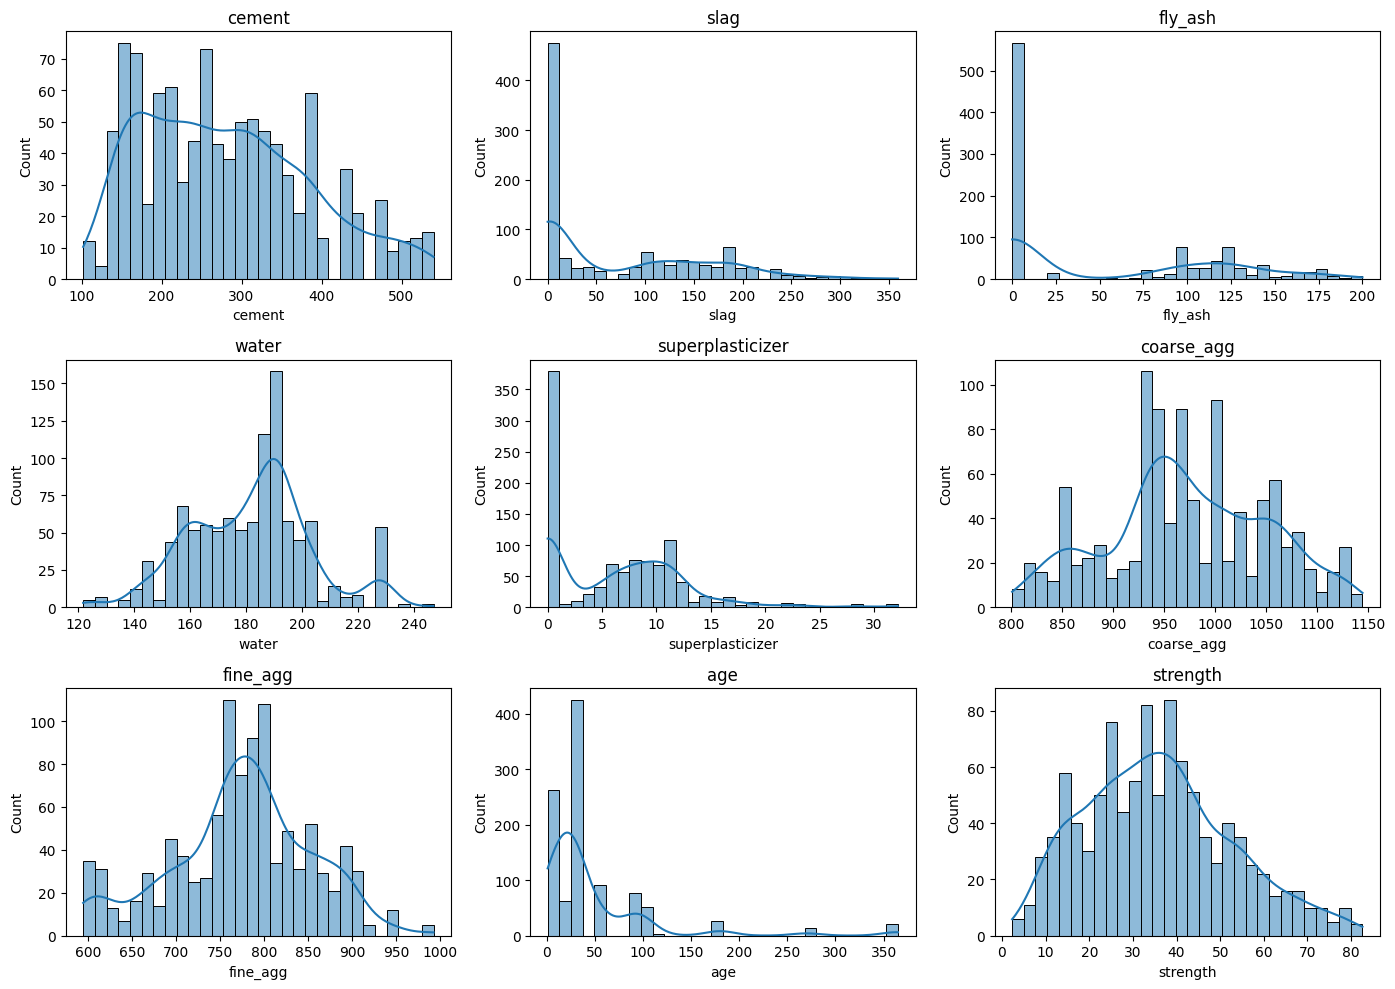

Share of rows equal to 0:
slag                0.452
fly_ash             0.550
superplasticizer    0.368
dtype: float64

Skewness:
cement              0.51
slag                0.80
fly_ash             0.54
water               0.07
superplasticizer    0.91
coarse_agg         -0.04
fine_agg           -0.25
age                 3.27
strength            0.42
dtype: float64


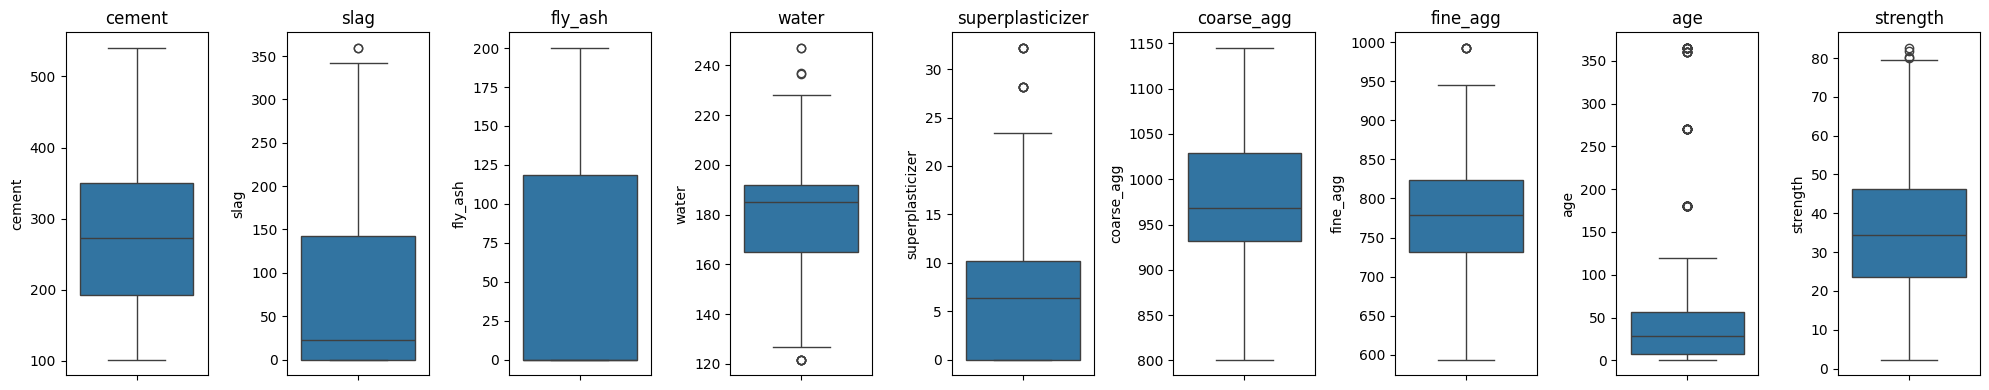


IQR outliers per variable:


,n_outliers,pct
cement,0,0.0
slag,2,0.2
fly_ash,0,0.0
water,9,0.9
superplasticizer,10,1.0
coarse_agg,0,0.0
fine_agg,5,0.5
age,59,5.7
strength,4,0.4


In [6]:
# --- 1. Inspect the duplicate rows ---
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print("Rows involved in duplication:", len(dups))
print("Extra copies:", df.duplicated().sum())
display(dups.head(12))
print("\nAge of the extra copies:")
print(df[df.duplicated()]["age"].value_counts().sort_index())

# --- 2. Distributions of every variable ---
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# --- 3. Share of zeros and skewness ---
print("Share of rows equal to 0:")
print((df[["slag", "fly_ash", "superplasticizer"]] == 0).mean().round(3))
print("\nSkewness:")
print(df.skew().round(2))

# --- 4. Outliers: boxplots and IQR counts ---
fig, axes = plt.subplots(1, 9, figsize=(20, 4))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({"n_outliers": df.apply(iqr_outliers)})
out["pct"] = (out["n_outliers"] / len(df) * 100).round(1)
print("\nIQR outliers per variable:")
display(out)

Duplicates

36 rows are involved in duplication, which comes to 11 distinct records with 25 extra copies.
The copies match on all 8 inputs and on strength to six decimal places (for example, 35.301171 MPa appears four times for the same mix at 3 days). Independent lab tests of the same mix would almost never agree that exactly, so these look like repeated entries and not true replicates.
The extra copies sit at ages 3, 7, 28, 56 and 91 days (5, 4, 6, 5 and 5 copies).
Planned decision (applied in the preparation step): remove them. Copies split across train and test would leak information and inflate the test score, and they would give those mixes extra weight in training.

Zeros

Zeros make up 45.2% of slag, 55.0% of fly_ash and 36.8% of superplasticizer. They mean the ingredient was not used, so they are real values and not missing data. We keep them as zeros.

Skewness

age is strongly right-skewed (3.27), consistent with a median of 28 days and a maximum of 365.
superplasticizer (0.91) and slag (0.80) are moderately right-skewed, and the target (0.42) is mildly so.
Water (0.07), coarse aggregate (−0.04) and fine aggregate (−0.25) are close to symmetric.

Outliers (IQR rule, on the full 1,030 rows)

age: 59 (5.7%), superplasticizer: 10, water: 9, fine_agg: 5, strength: 4, slag: 2. Cement, fly ash and coarse aggregate have none.
The age outliers are the long-curing tests: with Q3 at 56 days, the IQR rule flags ages above roughly 130 days. These are valid measurements, not errors.
Planned decision: keep all outliers. They are real, plausible mixes. Removing them would delete the extremes where the models are likely to struggle, and Task 2 asks us to find exactly those weak spots.

## 1C. Relationships between variables and strength

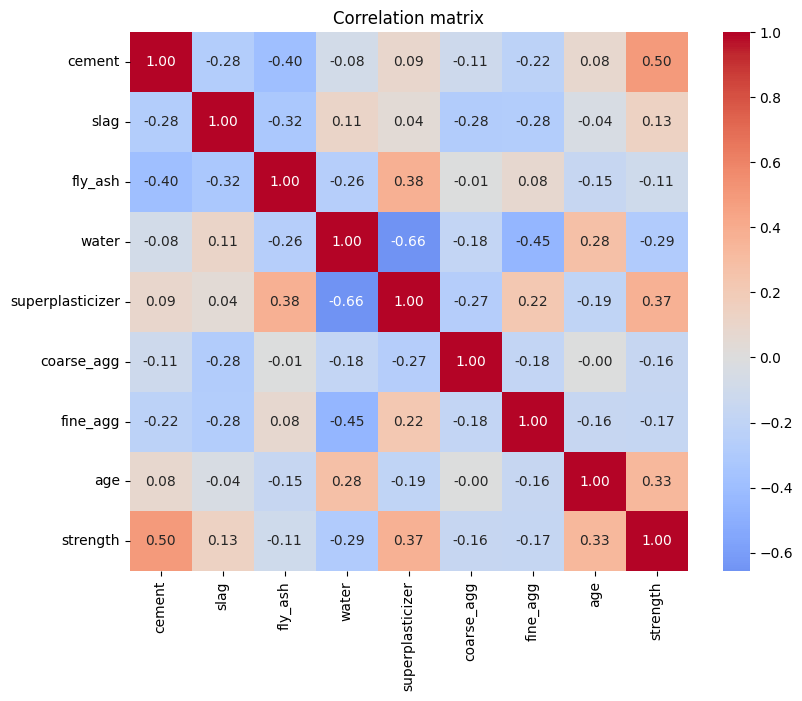

Correlation with strength:
cement              0.498
superplasticizer    0.366
age                 0.329
slag                0.135
fly_ash            -0.106
coarse_agg         -0.165
fine_agg           -0.167
water              -0.290
Name: strength, dtype: float64


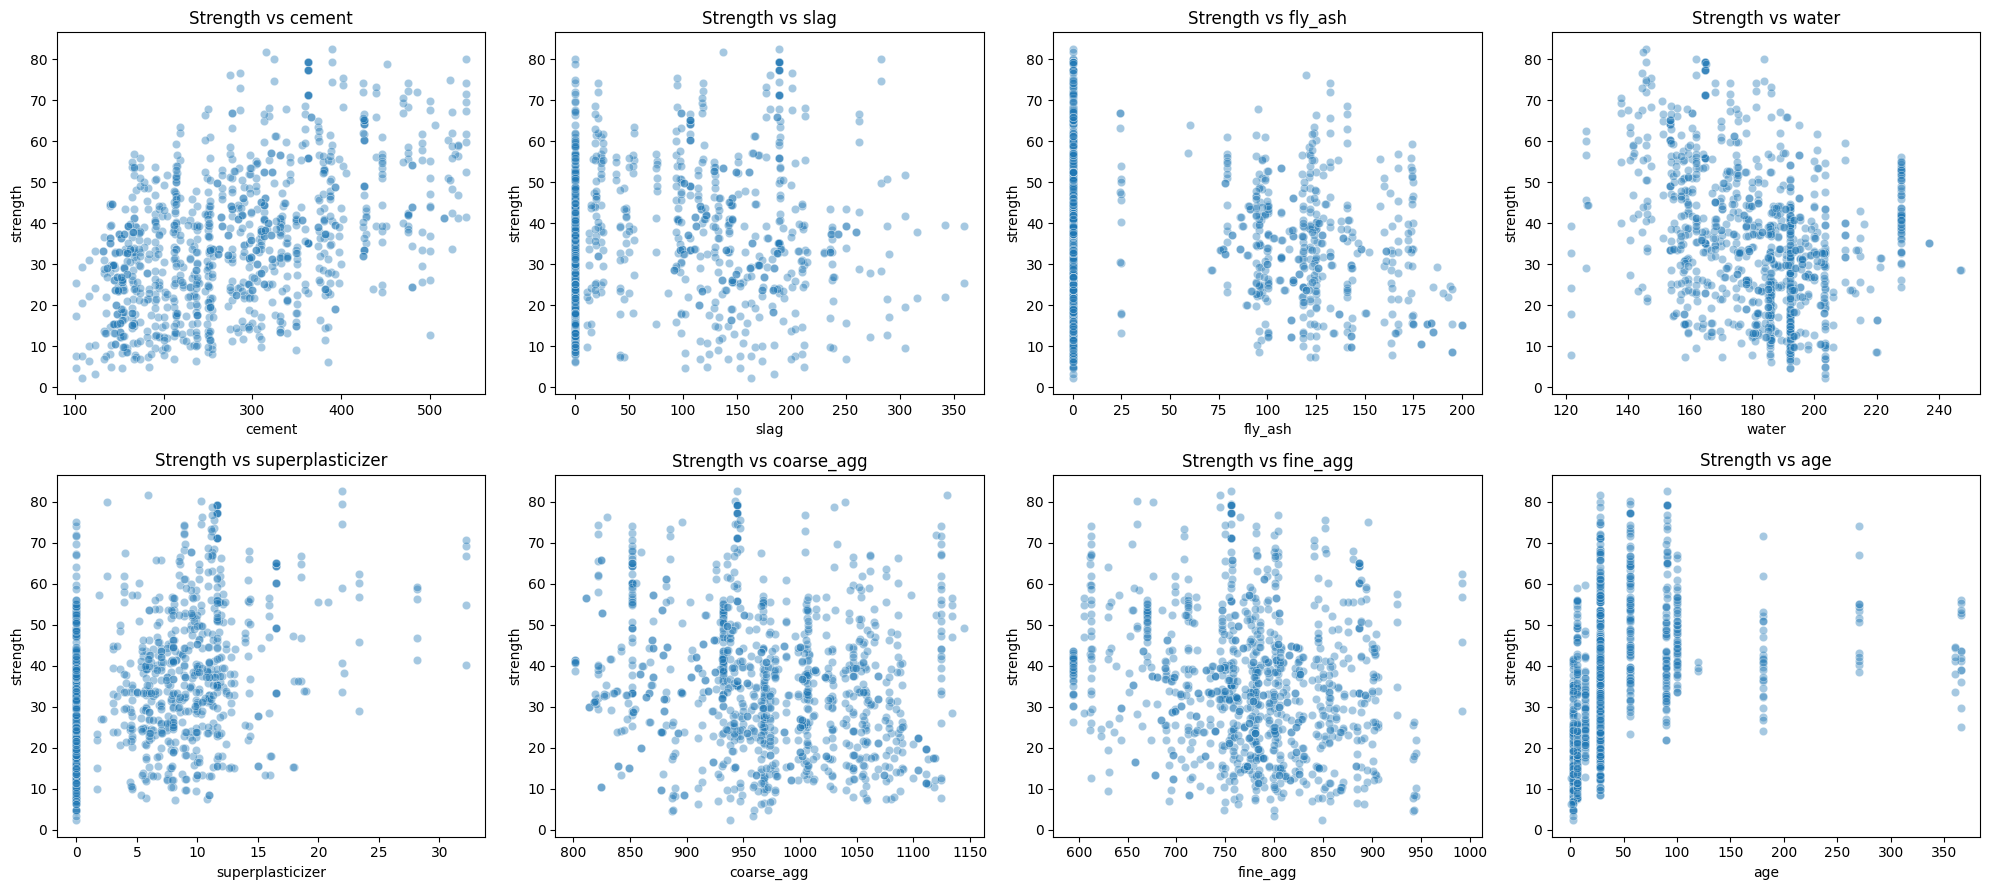

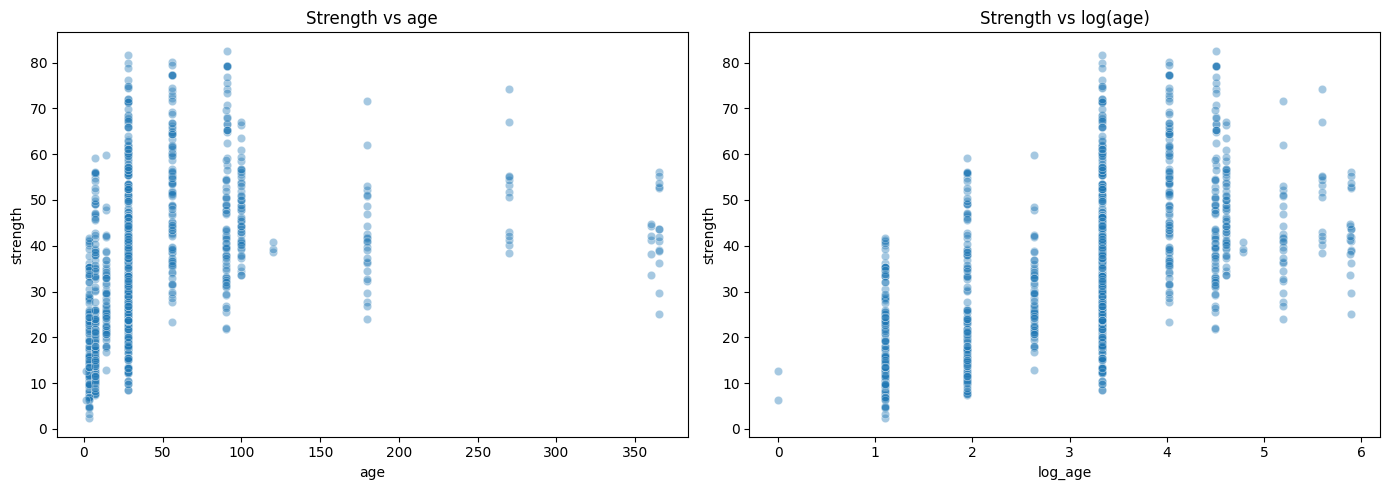

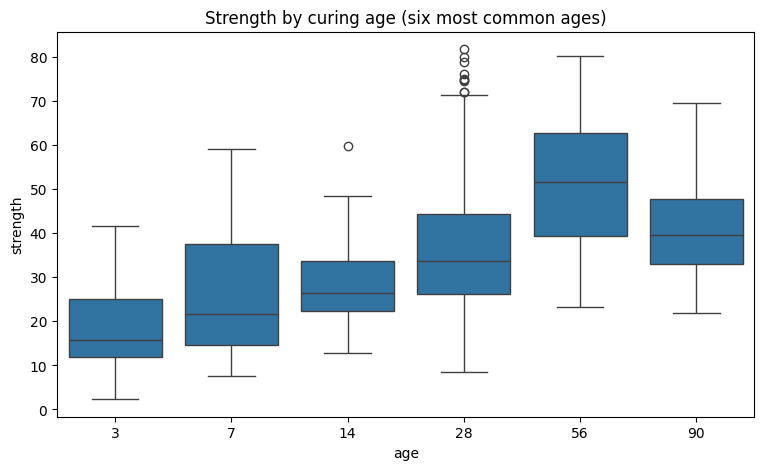

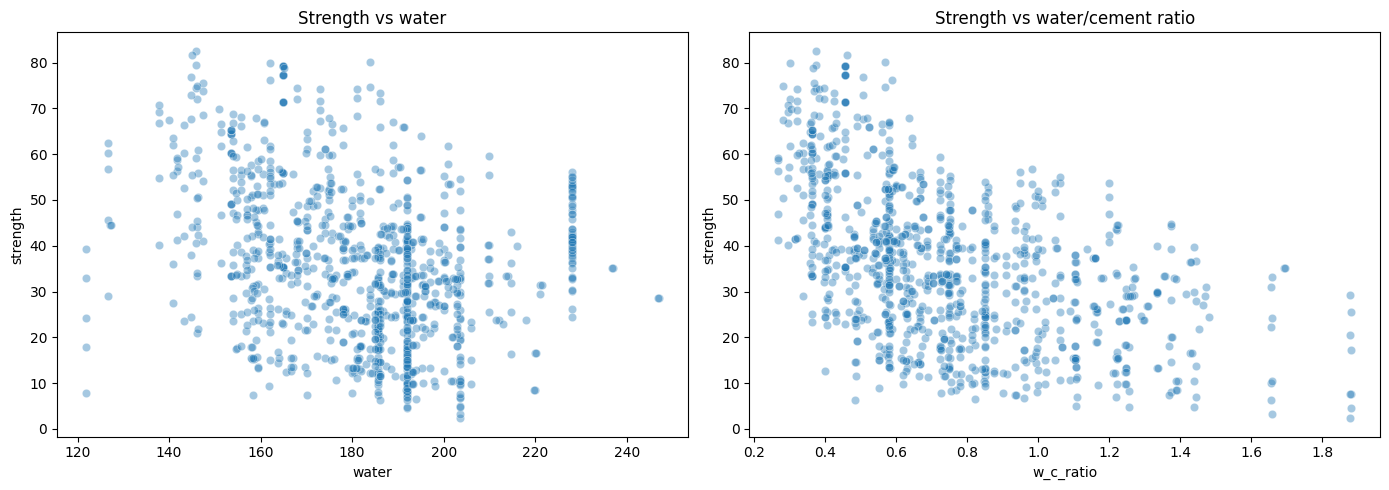

Correlation with strength:
  age       : 0.329
  log_age   : 0.552
  water     : -0.29
  w/c ratio : -0.501


In [7]:
# Temporary copy for exploration only (df itself is not modified)
eda = df.copy()
eda["log_age"] = np.log(eda["age"])
eda["w_c_ratio"] = eda["water"] / eda["cement"]

# --- 1. Correlation heatmap (original variables) ---
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print("Correlation with strength:")
print(df.corr()["strength"].drop("strength").sort_values(ascending=False).round(3))

# --- 2. Strength vs each ingredient ---
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), ["cement", "slag", "fly_ash", "water",
                                  "superplasticizer", "coarse_agg", "fine_agg", "age"]):
    sns.scatterplot(data=eda, x=col, y="strength", alpha=0.4, ax=ax)
    ax.set_title(f"Strength vs {col}")
plt.tight_layout()
plt.show()

# --- 3. Does a log scale for age help? ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=eda, x="age", y="strength", alpha=0.4, ax=axes[0])
axes[0].set_title("Strength vs age")
sns.scatterplot(data=eda, x="log_age", y="strength", alpha=0.4, ax=axes[1])
axes[1].set_title("Strength vs log(age)")
plt.tight_layout()
plt.show()

# --- 4. Strength by curing age (typical ages) ---
common_ages = eda["age"].value_counts().head(6).index.sort_values()
plt.figure(figsize=(9, 5))
sns.boxplot(data=eda[eda["age"].isin(common_ages)], x="age", y="strength")
plt.title("Strength by curing age (six most common ages)")
plt.show()

# --- 5. Water/cement ratio ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=eda, x="water", y="strength", alpha=0.4, ax=axes[0])
axes[0].set_title("Strength vs water")
sns.scatterplot(data=eda, x="w_c_ratio", y="strength", alpha=0.4, ax=axes[1])
axes[1].set_title("Strength vs water/cement ratio")
plt.tight_layout()
plt.show()

print("Correlation with strength:")
print("  age       :", round(eda["age"].corr(eda["strength"]), 3))
print("  log_age   :", round(eda["log_age"].corr(eda["strength"]), 3))
print("  water     :", round(eda["water"].corr(eda["strength"]), 3))
print("  w/c ratio :", round(eda["w_c_ratio"].corr(eda["strength"]), 3))

The heatmap and scatter plots didn’t arrive, so this rests on the printed correlations. Please make sure the plots are visible in your notebook, and if any of them contradicts a point below, tell me.

Single-variable correlations with strength (all 1,030 rows, before duplicates are removed)

Cement is the strongest positive correlate (+0.50), followed by superplasticizer (+0.37) and age (+0.33). More cement and longer curing go with higher strength, and superplasticizer is also associated with higher strength.
Water is the strongest negative correlate (−0.29), followed by fine aggregate (−0.17) and coarse aggregate (−0.17). More water means weaker concrete, which fits civil engineering theory.
Slag (+0.14) and fly ash (−0.11) are weakly correlated with strength on their own. They add strength slowly over time, so their effect depends on age and the rest of the mix, which a pairwise correlation does not capture.
The largest correlation is about 0.50, so no single variable explains strength well. That points to several variables acting together, and probably non-linearly.

### 1D. Data preparation (with justification)

In [8]:
from sklearn.model_selection import train_test_split

# --- 1. Remove exact duplicates ---
n_before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before} | after removing duplicates: {len(df_clean)} "
      f"| removed: {n_before - len(df_clean)}")
print("Duplicates remaining:", df_clean.duplicated().sum())

# --- 2. Outliers and zeros: deliberately kept (see justification in Markdown) ---

# --- 3. Feature engineering ---
df_clean["log_age"] = np.log(df_clean["age"])
df_clean["w_c_ratio"] = df_clean["water"] / df_clean["cement"]

# --- 4. Identify the mix (rows from the same mix measured at different ages) ---
mix_cols = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]
df_clean["mix_id"] = df_clean.groupby(mix_cols).ngroup()
print("\nDistinct mixes:", df_clean["mix_id"].nunique())
print("Measurements per mix:")
print(df_clean.groupby("mix_id").size().describe().round(2))

# --- 5. Check the new features for problems ---
print("\nNew features, summary:")
display(df_clean[["log_age", "w_c_ratio"]].describe().T)
print("Any infinite or missing values?",
      np.isinf(df_clean[["log_age", "w_c_ratio"]]).any().any() or df_clean.isna().any().any())

# --- 6. Features and target ---
base_features = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                 "coarse_agg", "fine_agg", "age"]
eng_features = base_features + ["log_age", "w_c_ratio"]
X = df_clean[eng_features]
y = df_clean["strength"]

# --- 7. Train/test split (80/20) BEFORE any scaling, so no test information leaks in ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)
print("Strength mean/std  train: %.2f / %.2f | test: %.2f / %.2f" %
      (y_train.mean(), y_train.std(), y_test.mean(), y_test.std()))

# --- 8. Save the cleaned data for traceability ---
df_clean.to_csv("concrete_clean.csv", index=False)
print("\nSaved cleaned data to concrete_clean.csv")

Rows before: 1030 | after removing duplicates: 1005 | removed: 25
Duplicates remaining: 0

Distinct mixes: 428
Measurements per mix:
count    428.00
mean       2.35
std        1.82
min        1.00
25%        1.00
50%        1.00
75%        4.00
max        8.00
dtype: float64

New features, summary:


,count,mean,std,min,25%,50%,75%,max
log_age,1005.0,3.168492,1.189466,0.000000,1.945910,3.332205,4.025352,5.899897
w_c_ratio,1005.0,0.756223,0.313524,0.266893,0.547465,0.689531,0.937530,1.882353


Any infinite or missing values? False

Train: (804, 10) | Test: (201, 10)
Strength mean/std  train: 35.07 / 16.02 | test: 35.98 / 17.32

Saved cleaned data to concrete_clean.csv


Duplicates: 25 exact copies were removed, leaving 1,005 rows. A check confirms 0 duplicates remain.

Features added: log_age and w_c_ratio. Neither has missing or infinite values. log_age runs from 0 (age 1 day) to 5.9 (365 days), and w_c_ratio from 0.27 to 1.88. There was no division by zero, because the minimum cement content is 102 kg/m³.

Split: 80/20 into 804 training and 201 test rows (seed 42). The split happens before any scaling, and the test set stays untouched until the final evaluation.

Saved: the cleaned data is stored as concrete_clean.csv, so the preparation can be traced.

### 1E. Mean-prediction baseline

Baseline prediction for every mix: 35.07 MPa


,RMSE,MAE,R2
5-fold CV (train),16.028,12.971,-0.010
Test,17.297,13.972,-0.003


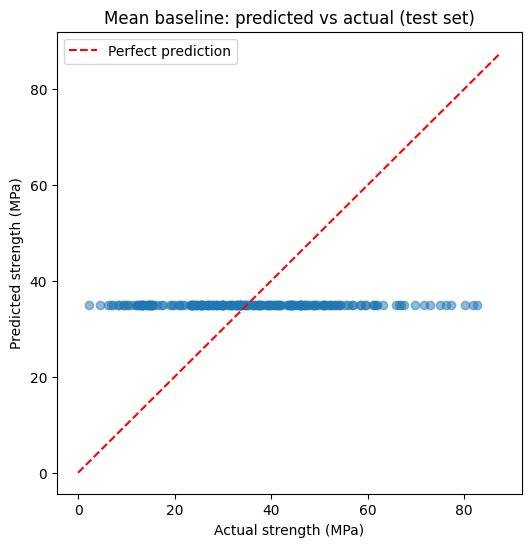

In [9]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Helper used for every model in Question 2 ---
def regression_report(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"RMSE": "neg_root_mean_squared_error",
           "MAE": "neg_mean_absolute_error",
           "R2": "r2"}

# --- Baseline: predict the training mean for every mix ---
baseline = DummyRegressor(strategy="mean")

# Cross-validated score on the training data
cv_res = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)
cv_base = {"RMSE": -cv_res["test_RMSE"].mean(),
           "MAE": -cv_res["test_MAE"].mean(),
           "R2": cv_res["test_R2"].mean()}

# Score on the held-out test set
baseline.fit(X_train, y_train)
test_base = regression_report(y_test, baseline.predict(X_test))

print("Baseline prediction for every mix: %.2f MPa" % baseline.constant_[0][0])
display(pd.DataFrame({"5-fold CV (train)": cv_base, "Test": test_base}).T.round(3))

# --- Visual: the baseline predicts a flat line ---
plt.figure(figsize=(6, 6))
plt.scatter(y_test, baseline.predict(X_test), alpha=0.5)
lims = [0, y_test.max() + 5]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Mean baseline: predicted vs actual (test set)")
plt.legend()
plt.show()

Baseline result

The baseline predicts the training mean, 35.07 MPa, for every mix.
5-fold CV on the training data: RMSE 16.03, MAE 12.97, R² −0.010.
Test set: RMSE 17.30, MAE 13.97, R² −0.003.

What the numbers mean

The baseline RMSE is almost the same as the standard deviation of strength (16.02 in training). That is expected, because predicting the mean leaves the whole spread unexplained.
R² is essentially zero, so the baseline explains none of the variation in strength. The tiny negative values are not meaningful. They arise because the test mean (35.98) differs slightly from the training mean (35.07).
The test RMSE is higher than the CV RMSE because the test set happens to be more spread out (SD 17.32). This is sampling variation in a small test set and not a fault in the baseline.

What the plot shows

The predictions form a flat horizontal line at about 35 MPa, crossing the perfect-prediction diagonal only near the mean.
The errors grow with distance from the mean. Weak mixes (about 5 to 15 MPa) are over-predicted by 20 to 30 MPa, and strong mixes (above 70 MPa) are under-predicted by 35 to 45 MPa.
Since the baseline ignores every input, any useful model must lift the points off this line and towards the diagonal.

Target to beat: CV RMSE below 16.0 MPa, test RMSE below 17.3 MPa, and R² above 0. In practice we expect to beat it by a wide margin.

## Question 2: Linear vs non-linear models

### 2A. Validation set-up and linear models

In [10]:
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# --- 1. Two validation schemes on the TRAINING data ---
#   Random 5-fold: rows of the same mix can fall in different folds (optimistic)
#   Grouped 5-fold: all rows of a mix stay together (mimics predicting a NEW mix)
groups_train = df_clean.loc[X_train.index, "mix_id"]
gcv = GroupKFold(n_splits=5)

cv_results = {}   # model name -> dict of CV scores

def cv_evaluate(name, model, feats):
    Xtr = X_train[feats]
    rand = cross_validate(model, Xtr, y_train, cv=cv, scoring=scoring)
    grp = cross_validate(model, Xtr, y_train, cv=gcv, groups=groups_train, scoring=scoring)
    cv_results[name] = {
        "Random CV RMSE": -rand["test_RMSE"].mean(),
        "Random CV RMSE (SD)": rand["test_RMSE"].std(),
        "Group CV RMSE": -grp["test_RMSE"].mean(),
        "Group CV RMSE (SD)": grp["test_RMSE"].std(),
        "Random CV MAE": -rand["test_MAE"].mean(),
        "Random CV R2": rand["test_R2"].mean(),
        "Group CV R2": grp["test_R2"].mean(),
    }

# --- 2. Multicollinearity check (VIF) ---
def vif_table(feats):
    Xc = sm.add_constant(X_train[feats])
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=feats).round(1)

print("VIF, raw 8 variables:")
print(vif_table(base_features).sort_values(ascending=False))
print("\nVIF, engineered set (adds log_age and w_c_ratio):")
print(vif_table(eng_features).sort_values(ascending=False))

# --- 3. Feature sets for the linear models ---
feats_A = base_features                                           # raw 8 variables
feats_B = [f for f in base_features if f != "age"] + ["log_age"]  # log(age) replaces age
feats_C = eng_features                                            # adds log_age and w_c_ratio

# --- 4. Fit/score: baseline and four linear specifications ---
cv_evaluate("Mean baseline", DummyRegressor(strategy="mean"), base_features)
cv_evaluate("Linear A: raw 8", make_pipeline(StandardScaler(), LinearRegression()), feats_A)
cv_evaluate("Linear B: log_age", make_pipeline(StandardScaler(), LinearRegression()), feats_B)
cv_evaluate("Linear C: log_age + w/c", make_pipeline(StandardScaler(), LinearRegression()), feats_C)
cv_evaluate("Ridge C: log_age + w/c",
            make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))), feats_C)

display(pd.DataFrame(cv_results).T.round(3))

# --- 5. Standardised coefficients of Linear C (MPa per 1 SD change) ---
lin_C = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train[feats_C], y_train)
print("\nStandardised coefficients, Linear C:")
print(pd.Series(lin_C[-1].coef_, index=feats_C).sort_values().round(2))

VIF, raw 8 variables:
slag                7.2
cement              7.1
fine_agg            7.1
water               6.9
fly_ash             6.1
coarse_agg          5.0
superplasticizer    2.9
age                 1.1
dtype: float64

VIF, engineered set (adds log_age and w_c_ratio):
cement              12.0
water                7.5
slag                 7.3
fine_agg             7.1
w_c_ratio            6.9
fly_ash              6.1
coarse_agg           5.0
superplasticizer     3.0
age                  2.7
log_age              2.5
dtype: float64


,Random CV RMSE,Random CV RMSE (SD),Group CV RMSE,Group CV RMSE (SD),Random CV MAE,Random CV R2,Group CV R2
Mean baseline,16.028,0.590,16.018,0.984,12.971,-0.010,-0.013
Linear A: raw 8,10.203,0.153,10.229,0.257,8.100,0.589,0.581
Linear B: log_age,7.027,0.246,7.158,0.265,5.409,0.805,0.796
Linear C: log_age + w/c,6.852,0.178,6.994,0.370,5.362,0.815,0.806
Ridge C: log_age + w/c,6.853,0.175,6.997,0.371,5.363,0.815,0.806



Standardised coefficients, Linear C:
age                 -2.39
w_c_ratio           -2.20
water               -1.82
superplasticizer     0.58
coarse_agg           2.01
fine_agg             2.66
fly_ash              5.75
slag                 9.53
log_age             11.74
cement              11.85
dtype: float64


The best linear model is Linear C (CV RMSE about 6.9 MPa, R² about 0.81), a 57% error reduction on the baseline.
The remaining error is still large (about 19% of the variation unexplained). A linear model assumes that each ingredient adds to strength independently, whereas in practice slag and fly ash act slowly and depend on age and the rest of the mix. This is the case for testing non-linear models next

### 2B. Non-linear models

,Random CV RMSE,Random CV RMSE (SD),Group CV RMSE,Group CV RMSE (SD),Random CV MAE,Random CV R2,Group CV R2
Mean baseline,16.028,0.590,16.018,0.984,12.971,-0.010,-0.013
Linear A: raw 8,10.203,0.153,10.229,0.257,8.100,0.589,0.581
Linear B: log_age,7.027,0.246,7.158,0.265,5.409,0.805,0.796
Linear C: log_age + w/c,6.852,0.178,6.994,0.370,5.362,0.815,0.806
Ridge C: log_age + w/c,6.853,0.175,6.997,0.371,5.363,0.815,0.806
Poly-2 Ridge (log_age + w/c),5.555,0.293,6.272,0.678,4.235,0.878,0.843
Random Forest: raw 8,5.348,0.491,6.102,0.642,3.876,0.886,0.852
Random Forest: log_age + w/c,5.134,0.350,5.765,0.619,3.702,0.896,0.867
Gradient Boosting: raw 8,4.777,0.431,5.858,0.677,3.454,0.910,0.864
Gradient Boosting: log_age + w/c,4.710,0.322,5.527,0.699,3.395,0.912,0.878



Grouped minus random CV RMSE (positive = random CV is optimistic):
Mean baseline                      -0.010
Linear A: raw 8                     0.026
Linear B: log_age                   0.131
Linear C: log_age + w/c             0.142
Ridge C: log_age + w/c              0.144
Poly-2 Ridge (log_age + w/c)        0.717
Random Forest: raw 8                0.754
Random Forest: log_age + w/c        0.631
Gradient Boosting: raw 8            1.081
Gradient Boosting: log_age + w/c    0.817
dtype: float64


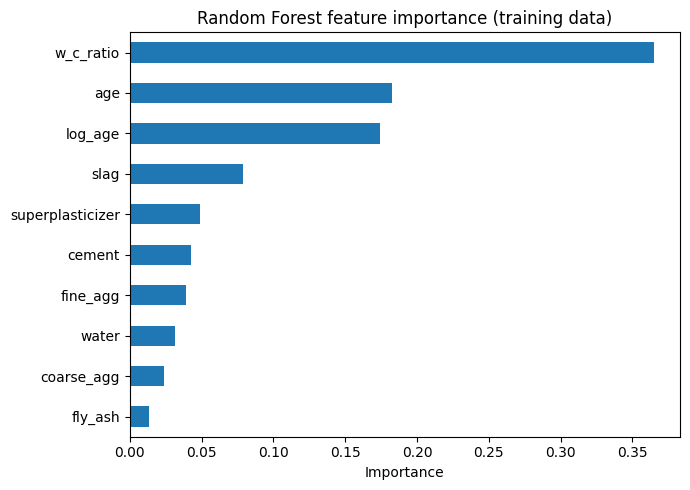

w_c_ratio           0.365
age                 0.183
log_age             0.175
slag                0.079
superplasticizer    0.049
cement              0.043
fine_agg            0.039
water               0.031
coarse_agg          0.024
fly_ash             0.013
dtype: float64


In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# --- 1. Non-linear models, scored with the same two CV schemes as the linear ones ---

# Bridge model: a linear model with all squared and interaction terms (regularised)
cv_evaluate("Poly-2 Ridge (log_age + w/c)",
            make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                          StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))), feats_C)

# Tree ensembles: no scaling needed. Evaluated on raw features and on engineered features,
# to test whether log_age / w_c_ratio still help once the model can learn curves itself.
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
gb = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                               subsample=0.8, random_state=SEED)

cv_evaluate("Random Forest: raw 8", rf, base_features)
cv_evaluate("Random Forest: log_age + w/c", rf, feats_C)
cv_evaluate("Gradient Boosting: raw 8", gb, base_features)
cv_evaluate("Gradient Boosting: log_age + w/c", gb, feats_C)

res = pd.DataFrame(cv_results).T.round(3)
display(res[["Random CV RMSE", "Random CV RMSE (SD)", "Group CV RMSE",
             "Group CV RMSE (SD)", "Random CV MAE", "Random CV R2", "Group CV R2"]])

# --- 2. Gap between random and grouped CV (a large gap = the model memorises mixes) ---
gap = (res["Group CV RMSE"] - res["Random CV RMSE"]).round(3)
print("\nGrouped minus random CV RMSE (positive = random CV is optimistic):")
print(gap)

# --- 3. What the best tree model relies on ---
rf_fit = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train[feats_C], y_train)
imp = pd.Series(rf_fit.feature_importances_, index=feats_C).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title="Random Forest feature importance (training data)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).round(3))

Non-linear models beat the linear model, but by less than random CV suggests.

Under random CV, the best model (Gradient Boosting) cuts RMSE from 6.85 to 4.71 MPa, a 31% reduction. Under grouped CV, which better reflects predicting a new mix, it falls from 6.99 to 5.53, a 21% reduction.
The grouped-minus-random gap is about 0.14 MPa for the linear models but 0.6 to 1.1 MPa for the non-linear ones. The flexible models partly exploit the fact that other ages of the same mix sit in the training folds. This confirms the concern from 1D, so grouped CV is the honest estimate, and random CV is reported only for comparison.

2. Non-linearity is real, and it comes in layers.

A polynomial model with squares and interactions (Poly-2 Ridge) improves on Linear C (6.99 to 6.27), so some of the gain comes from curvature and interactions between ingredients, such as slag and fly ash acting differently at different ages.
The tree ensembles go further (5.5 to 5.9), so the structure is more complex than quadratic terms capture.

3. Gradient Boosting leads, but the margins between the top models are small.

Gradient Boosting beats Random Forest in all four comparisons (both feature sets, both CV schemes), but the difference in grouped CV is only about 0.2 to 0.25 MPa. The fold-to-fold SD is about 0.6 to 0.7, so this gap is within the noise. We should call the two models comparable, and test the difference more carefully in 2C.
The gain over the linear model (about 1.5 MPa under grouped CV) is more than twice that fold-to-fold SD, so it is more convincing.

4. The engineered features still help the tree models.

Adding log_age and w_c_ratio lowers grouped RMSE by about 0.33 MPa for both Random Forest (6.10 to 5.77) and Gradient Boosting (5.86 to 5.53). The effect is consistent across both models and both CV schemes, though modest relative to the SD. Trees can learn curves themselves, but a ratio of two variables is something a tree struggles to build from splits, so it helps.

5. Feature importance (Random Forest)

w_c_ratio is the top feature (0.365). age (0.183) and log_age (0.175) are second and third, but they carry the same information, so their combined importance of about 0.36 matches the water/cement ratio. Slag (0.079), superplasticizer (0.049) and cement (0.043) follow. Fly ash (0.013) and coarse aggregate (0.024) contribute little.
Cautions. Importance scores show what the model uses, not what causes strength. Correlated features share importance, so cement looks weak partly because w_c_ratio absorbs it. The scores also give no direction of effect. This matters for Question 3.

### 2C. Tuning and final test evaluation,

Best parameters: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 400}
Best grouped-CV RMSE: 5.368  (default GB was 5.527)


,params,std_test_score,RMSE
5,"{'learning_rate': 0.03, 'max_depth': 4, 'n_est...",0.669,5.368
15,"{'learning_rate': 0.06, 'max_depth': 5, 'n_est...",0.679,5.399
11,"{'learning_rate': 0.06, 'max_depth': 3, 'n_est...",0.754,5.415
7,"{'learning_rate': 0.03, 'max_depth': 5, 'n_est...",0.640,5.419
17,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.831,5.444


,Test RMSE,RMSE 95% CI,Test MAE,Test R2
Model,,,,
Mean baseline,17.297,15.68 to 18.91,13.972,-0.003
Linear C,7.448,6.58 to 8.37,5.769,0.814
Poly-2 Ridge,6.052,5.12 to 6.97,4.416,0.877
Random Forest,4.860,3.92 to 5.84,3.359,0.921
Gradient Boosting (default),4.646,3.89 to 5.40,3.351,0.928
Gradient Boosting (tuned),4.279,3.46 to 5.14,2.944,0.939



Improvement in RMSE over Linear C (positive = better), with 95% CI:
  Poly-2 Ridge                    1.42 MPa  [ 0.83,  2.02]
  Random Forest                   2.61 MPa  [ 1.92,  3.31]
  Gradient Boosting (default)     2.81 MPa  [ 2.13,  3.47]
  Gradient Boosting (tuned)       3.18 MPa  [ 2.43,  3.95]

Gradient Boosting (tuned) vs Random Forest:
   0.57 MPa  [ 0.21,  0.93]


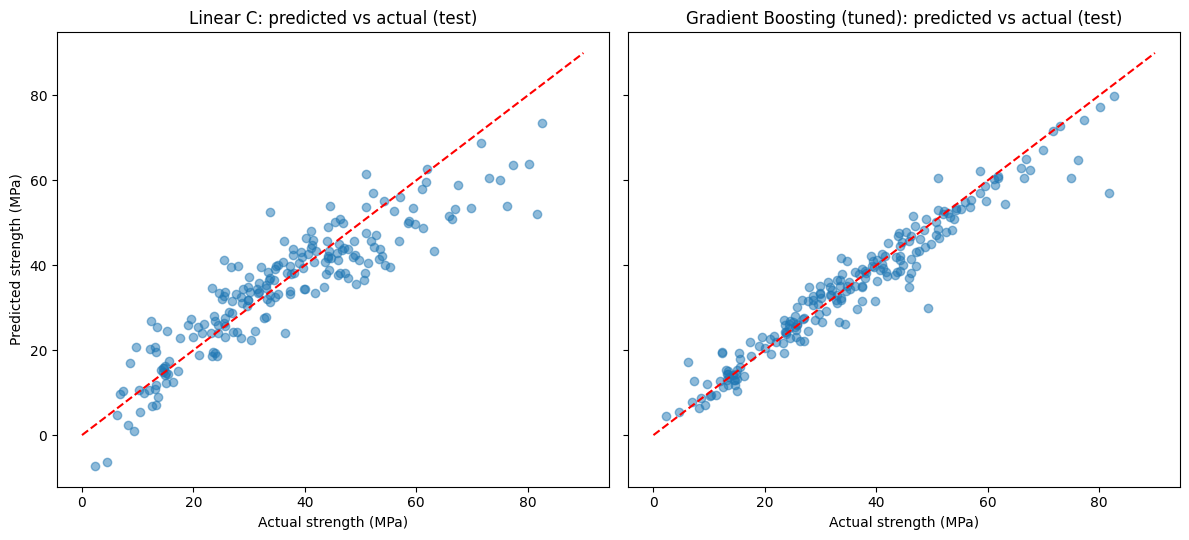

In [12]:
from sklearn.model_selection import GridSearchCV

# --- 1. Light tuning of Gradient Boosting, using GROUPED CV on training data only ---
param_grid = {"n_estimators": [200, 400],
              "learning_rate": [0.03, 0.06, 0.1],
              "max_depth": [2, 3, 4, 5]}
gs = GridSearchCV(GradientBoostingRegressor(subsample=0.8, random_state=SEED),
                  param_grid, cv=gcv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train[feats_C], y_train, groups=groups_train)

print("Best parameters:", gs.best_params_)
print("Best grouped-CV RMSE: %.3f  (default GB was 5.527)" % -gs.best_score_)
top = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head(5)
display(top[["params", "mean_test_score", "std_test_score"]].assign(
    RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(3))

# --- 2. Fit all candidates on the full training set; score once on the test set ---
models = {
    "Mean baseline": (DummyRegressor(strategy="mean"), base_features),
    "Linear C": (make_pipeline(StandardScaler(), LinearRegression()), feats_C),
    "Poly-2 Ridge": (make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                                   StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))), feats_C),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), feats_C),
    "Gradient Boosting (default)": (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                    max_depth=3, subsample=0.8, random_state=SEED), feats_C),
    "Gradient Boosting (tuned)": (GradientBoostingRegressor(subsample=0.8, random_state=SEED,
                                  **gs.best_params_), feats_C),
}
test_preds, fitted = {}, {}
for name, (m, feats) in models.items():
    m.fit(X_train[feats], y_train)
    fitted[name] = m
    test_preds[name] = m.predict(X_test[feats])

# --- 3. Bootstrap 95% intervals on the test set (201 rows, so uncertainty is real) ---
yt = y_test.values
B, n = 2000, len(yt)
idx = np.random.default_rng(SEED).integers(0, n, size=(B, n))
def boot_rmse(p):
    return np.sqrt(((yt[idx] - p[idx]) ** 2).mean(axis=1))

rows, boots = [], {}
for name, p in test_preds.items():
    boots[name] = boot_rmse(p)
    rep = regression_report(y_test, p)
    lo, hi = np.percentile(boots[name], [2.5, 97.5])
    rows.append({"Model": name, "Test RMSE": rep["RMSE"], "RMSE 95% CI": f"{lo:.2f} to {hi:.2f}",
                 "Test MAE": rep["MAE"], "Test R2": rep["R2"]})
display(pd.DataFrame(rows).set_index("Model").round(3))

# --- 4. Paired comparison against Linear C (same bootstrap samples) ---
print("\nImprovement in RMSE over Linear C (positive = better), with 95% CI:")
for name in ["Poly-2 Ridge", "Random Forest", "Gradient Boosting (default)", "Gradient Boosting (tuned)"]:
    d = boots["Linear C"] - boots[name]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"  {name:30s} {d.mean():5.2f} MPa  [{lo:5.2f}, {hi:5.2f}]")

print("\nGradient Boosting (tuned) vs Random Forest:")
d = boots["Random Forest"] - boots["Gradient Boosting (tuned)"]
print(f"  {d.mean():5.2f} MPa  [{np.percentile(d, 2.5):5.2f}, {np.percentile(d, 97.5):5.2f}]")

# --- 5. Predicted vs actual: linear vs tuned boosting ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["Linear C", "Gradient Boosting (tuned)"]):
    ax.scatter(y_test, test_preds[name], alpha=0.5)
    lims = [0, 90]
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name}: predicted vs actual (test)")
    ax.set_xlabel("Actual strength (MPa)")
axes[0].set_ylabel("Predicted strength (MPa)")
plt.tight_layout()
plt.show()

The best Gradient Boosting setting (learning rate 0.03, depth 4, 400 trees) scores a grouped-CV RMSE of 5.37, against 5.53 for the default.
The top five settings are all within 0.08 MPa of each other (5.37 to 5.44), and the fold-to-fold SD is about 0.65. The performance surface is flat, so tuning gives only a small, uncertain gain. Because we picked the best of 24 settings on the same folds, 5.37 is also slightly optimistic.

### 2D. Sensitivity analysis

In [13]:
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

best = gs.best_params_
def make_models():
    return {
        "Linear C": (make_pipeline(StandardScaler(), LinearRegression()), feats_C),
        "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), feats_C),
        "Gradient Boosting (tuned)": (GradientBoostingRegressor(subsample=0.8, random_state=SEED, **best), feats_C),
    }

rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
Xall, yall, gall = df_clean[feats_C], df_clean["strength"], df_clean["mix_id"]

# --- 1. Repeated hold-out: random-by-row vs grouped-by-mix (10 splits each, 20% held out) ---
def repeated_holdout(splitter, groups=None):
    rows = []
    for k, (tr, te) in enumerate(splitter.split(Xall, yall, groups)):
        for name, (m, f) in make_models().items():
            m.fit(Xall.iloc[tr][f], yall.iloc[tr])
            rows.append({"split": k, "Model": name, "RMSE": rmse(yall.iloc[te], m.predict(Xall.iloc[te][f]))})
    return pd.DataFrame(rows)

rand_h = repeated_holdout(ShuffleSplit(n_splits=10, test_size=0.2, random_state=SEED))
grp_h  = repeated_holdout(GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=SEED), gall)

summary = pd.concat({
    "Random split (RMSE mean)": rand_h.groupby("Model")["RMSE"].mean(),
    "Random split (SD)":        rand_h.groupby("Model")["RMSE"].std(),
    "Grouped split (RMSE mean)": grp_h.groupby("Model")["RMSE"].mean(),
    "Grouped split (SD)":        grp_h.groupby("Model")["RMSE"].std(),
}, axis=1)
summary["Optimism (grouped - random)"] = summary["Grouped split (RMSE mean)"] - summary["Random split (RMSE mean)"]
print("Repeated hold-out, 10 splits each:")
display(summary.round(2))

# Does the model ranking hold in every grouped split?
piv = grp_h.pivot(index="split", columns="Model", values="RMSE")
print("\nGrouped splits where tuned boosting beats Linear C:",
      int((piv["Gradient Boosting (tuned)"] < piv["Linear C"]).sum()), "of 10")
print("Grouped splits where tuned boosting beats Random Forest:",
      int((piv["Gradient Boosting (tuned)"] < piv["Random Forest"]).sum()), "of 10")

# --- 2. Duplicates: removed (1005 rows) vs retained (1030 rows), same CV on the full data ---
df_dup = df.copy()
df_dup["log_age"] = np.log(df_dup["age"])
df_dup["w_c_ratio"] = df_dup["water"] / df_dup["cement"]
df_dup["mix_id"] = df_dup.groupby(mix_cols).ngroup()

def full_data_cv(data):
    X_, y_, g_ = data[feats_C], data["strength"], data["mix_id"]
    out = {}
    for name in ["Linear C", "Gradient Boosting (tuned)"]:
        m, f = make_models()[name]
        r = cross_validate(m, X_, y_, cv=KFold(5, shuffle=True, random_state=SEED), scoring=scoring)
        g = cross_validate(m, X_, y_, cv=GroupKFold(5), groups=g_, scoring=scoring)
        out[name] = {"Random CV RMSE": -r["test_RMSE"].mean(), "Group CV RMSE": -g["test_RMSE"].mean()}
    return pd.DataFrame(out).T

print("\nDuplicates removed (1,005 rows):")
display(full_data_cv(df_clean).round(3))
print("Duplicates retained (1,030 rows):")
display(full_data_cv(df_dup).round(3))

Repeated hold-out, 10 splits each:


,Random split (RMSE mean),Random split (SD),Grouped split (RMSE mean),Grouped split (SD),Optimism (grouped - random)
Model,,,,,
Gradient Boosting (tuned),4.37,0.35,5.53,0.56,1.16
Linear C,7.09,0.24,7.10,0.38,0.02
Random Forest,5.00,0.33,5.58,0.66,0.59



Grouped splits where tuned boosting beats Linear C: 10 of 10
Grouped splits where tuned boosting beats Random Forest: 5 of 10

Duplicates removed (1,005 rows):


,Random CV RMSE,Group CV RMSE
Linear C,6.947,7.023
Gradient Boosting (tuned),4.236,5.219


Duplicates retained (1,030 rows):


,Random CV RMSE,Group CV RMSE
Linear C,7.023,7.195
Gradient Boosting (tuned),4.437,5.396


Findings

Random splits flatter the flexible models. Linear C scores the same under both schemes. Random Forest looks 0.6 MPa better and boosting 1.2 MPa better under random splits, because they can partly recognise mixes seen at other ages. For a genuinely new mix, the realistic RMSE is about 5.5 MPa for boosting or forest and about 7.1 MPa for the linear model.

The non-linear advantage is robust. Tuned boosting beat Linear C in 10 of 10 grouped splits, with a mean RMSE 1.57 MPa lower (a 22% reduction).

Boosting and Random Forest are comparable. Boosting won only 5 of 10 grouped splits, and the means (5.53 and 5.58) differ far less than the split-to-split SD (0.56 to 0.66). We do not claim that either is better.

The duplicates decision does not affect the conclusions. Retaining the 25 duplicates changed CV RMSE by less than 0.2 MPa, within fold-to-fold variation. The rankings and conclusions were identical. The duplicates are removed on principle (repeated entries, not independent tests), not because of a measured accuracy gain.

The main findings are stable: non-linear models outperform linear models, the ranking holds across splits, and the grouped figures are the honest estimate of performance on new mixes. The headline test RMSE of 4.28 MPa is optimistic in absolute terms.

Limitations

The boosting hyperparameters were tuned on data that overlaps these hold-out sets. This could only favour boosting, and it still only tied the forest.

Ten splits give a rough estimate of variability, not a precise one.

### 2E. Residual inspection

,Linear C,Gradient Boosting
RMSE,7.042,5.238
MAE,5.521,3.752
Mean residual (bias),-0.023,-0.016
SD,7.046,5.240
Skewness,0.341,0.147
Excess kurtosis,0.522,2.877
Largest |residual|,29.741,28.145
Share |res| > 10 MPa (%),15.721,6.866


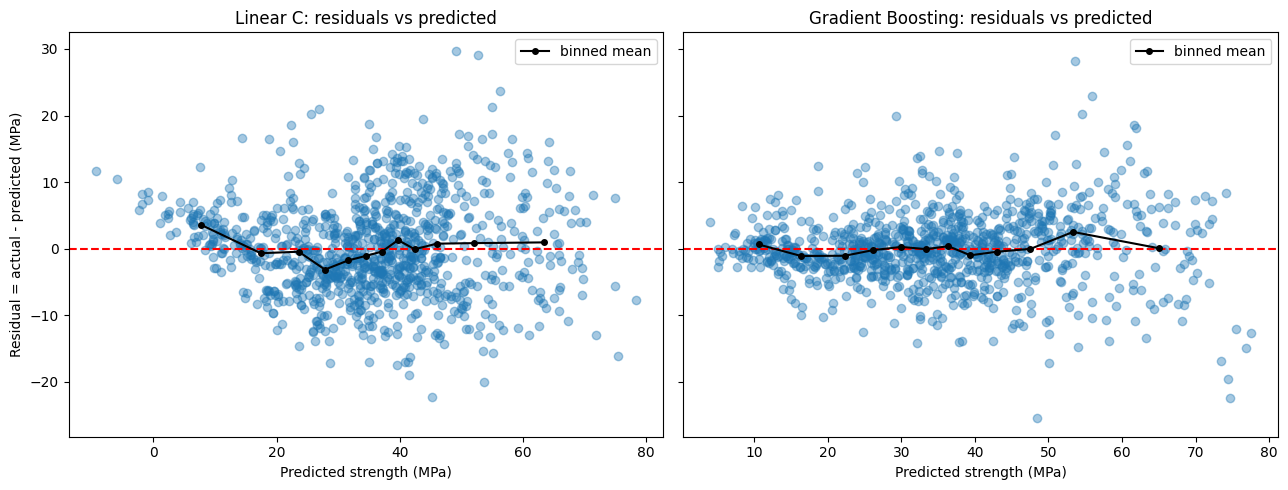

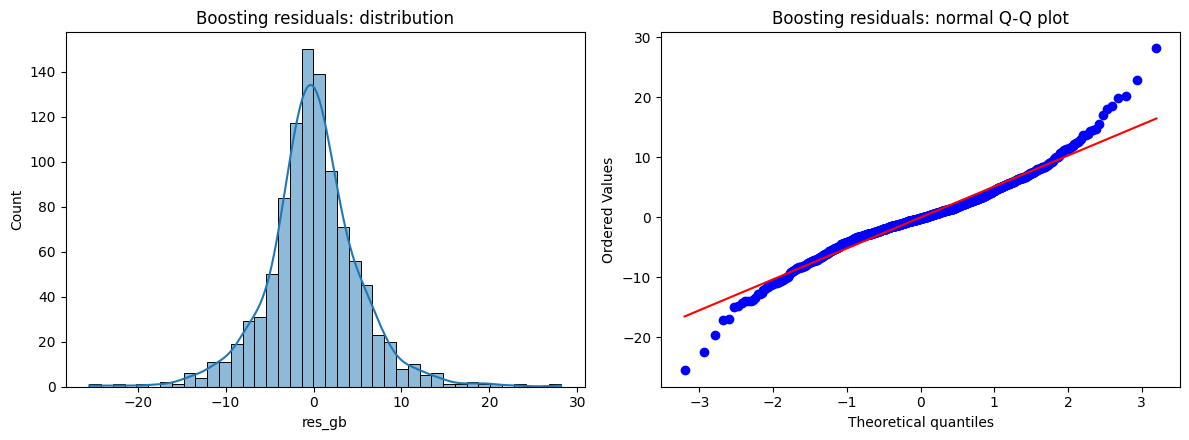

Linear C           Spearman |residual| vs predicted: +0.22 (p=4.11e-12) | vs age: +0.17 (p=5.7e-08)
Gradient Boosting  Spearman |residual| vs predicted: +0.32 (p=7.95e-25) | vs age: +0.10 (p=0.00251)
Linear C           share of squared error that is common to the whole mix (rows in multi-age mixes): 0.68
Gradient Boosting  share of squared error that is common to the whole mix (rows in multi-age mixes): 0.65


In [14]:
from sklearn.model_selection import cross_val_predict
from scipy import stats

# --- 1. Out-of-fold predictions (grouped by mix) for the linear and boosting models ---
gb_best = GradientBoostingRegressor(subsample=0.8, random_state=SEED, **best)
lin_c = make_pipeline(StandardScaler(), LinearRegression())
gkf = GroupKFold(n_splits=5)

res_df = df_clean[["cement", "water", "age", "w_c_ratio", "mix_id", "strength"]].copy()
res_df["pred_lin"] = cross_val_predict(lin_c, Xall, yall, cv=gkf, groups=gall)
res_df["pred_gb"] = cross_val_predict(gb_best, Xall, yall, cv=gkf, groups=gall)
res_df["res_lin"] = res_df["strength"] - res_df["pred_lin"]   # actual - predicted
res_df["res_gb"] = res_df["strength"] - res_df["pred_gb"]

# --- 2. Overall residual summary ---
summ = pd.DataFrame({
    m: {"RMSE": np.sqrt((res_df[c] ** 2).mean()),
        "MAE": res_df[c].abs().mean(),
        "Mean residual (bias)": res_df[c].mean(),
        "SD": res_df[c].std(),
        "Skewness": stats.skew(res_df[c]),
        "Excess kurtosis": stats.kurtosis(res_df[c]),
        "Largest |residual|": res_df[c].abs().max(),
        "Share |res| > 10 MPa (%)": (res_df[c].abs() > 10).mean() * 100}
    for m, c in [("Linear C", "res_lin"), ("Gradient Boosting", "res_gb")]}).round(3)
display(summ)

# --- 3. Residuals vs predicted (look for curves and fanning) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (m, pc, rc) in zip(axes, [("Linear C", "pred_lin", "res_lin"),
                                  ("Gradient Boosting", "pred_gb", "res_gb")]):
    ax.scatter(res_df[pc], res_df[rc], alpha=0.4)
    ax.axhline(0, color="red", ls="--")
    # running mean of the residuals (binned) to reveal systematic curvature
    b = pd.qcut(res_df[pc], 12)
    ax.plot(res_df.groupby(b, observed=True)[pc].mean(),
            res_df.groupby(b, observed=True)[rc].mean(), "k-o", ms=4, label="binned mean")
    ax.set_title(f"{m}: residuals vs predicted")
    ax.set_xlabel("Predicted strength (MPa)")
    ax.legend()
axes[0].set_ylabel("Residual = actual - predicted (MPa)")
plt.tight_layout(); plt.show()

# --- 4. Normality of the boosting residuals ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(res_df["res_gb"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Boosting residuals: distribution")
stats.probplot(res_df["res_gb"], dist="norm", plot=axes[1])
axes[1].set_title("Boosting residuals: normal Q-Q plot")
plt.tight_layout(); plt.show()

# --- 5. Does the error size change with the prediction level or with age? (heteroscedasticity) ---
for m, pc, rc in [("Linear C", "pred_lin", "res_lin"), ("Gradient Boosting", "pred_gb", "res_gb")]:
    r1, p1 = stats.spearmanr(res_df[pc], res_df[rc].abs())
    r2, p2 = stats.spearmanr(res_df["age"], res_df[rc].abs())
    print(f"{m:18s} Spearman |residual| vs predicted: {r1:+.2f} (p={p1:.3g}) | vs age: {r2:+.2f} (p={p2:.3g})")

# --- 6. Are residuals correlated within a mix? (violates independence) ---
for m, rc in [("Linear C", "res_lin"), ("Gradient Boosting", "res_gb")]:
    mix_mean = res_df.groupby("mix_id")[rc].transform("mean")
    multi = res_df.groupby("mix_id")[rc].transform("size") > 1
    share = (mix_mean[multi] ** 2).mean() / (res_df.loc[multi, rc] ** 2).mean()
    print(f"{m:18s} share of squared error that is common to the whole mix "
          f"(rows in multi-age mixes): {share:.2f}")

Findings

No overall bias. Both models are correct on average (mean residual about −0.02 MPa).
Boosting has smaller typical errors. MAE is about a third lower, and the share of predictions off by more than 10 MPa falls from 15.7% to 6.9%.
Boosting does not fix the worst cases. Its largest error (28.1 MPa) is almost the same as the linear model’s (29.7 MPa).
Boosting’s errors have heavy tails (excess kurtosis 2.88). Most predictions are accurate, but a minority are badly wrong. Linear C’s errors are close to normal.
Error grows with predicted strength (Spearman +0.22 and +0.32) and slightly with age (+0.17 and +0.10). The p-values are tiny only because there are 1,005 rows. The correlations show these are modest tendencies, not strong patterns.
Residuals are not independent within a mix. About 65 to 68% of the squared error in multi-age mixes is common to the whole mix. If errors were independent across a mix’s rows, this share would be much lower (roughly 0.25 to 0.4 for typical mixes, my own approximation). When the model is wrong about a mix, it tends to be wrong at all of that mix’s ages.

Limitations

The residual plots (residuals vs predicted, histogram, Q-Q plot) must be included in the notebook as visual evidence. These findings rest on the printed statistics, and the plots should be checked against them, in particular for curvature in the Linear C residuals.
A likely explanation for the shared-by-mix error is that mix-level factors are missing from the 8 variables, such as cement type, aggregate properties or lab conditions. This is a hypothesis, because the data cannot test it.

Conclusion

Both models are unbiased on average, so the question is where and how much they err, not whether they lean one way.
Gradient Boosting is more accurate in the typical case but still produces occasional large misses. For practical use, report its error as a distribution (MAE of about 3.8 MPa, with about 7% of predictions off by more than 10 MPa) and not as a single RMSE.
Prediction is less reliable for stronger mixes, and slightly less for older specimens. Section 2F quantifies this by group.
The residuals violate independence. The data hold only 428 independent mixes, so uncertainty is larger than 1,005 rows would suggest, and the bootstrap intervals in 2C are probably too narrow. This supports using grouped validation throughout.

### 2F. Where are predictions weakest?

Check (expect ~7.04 and ~5.24): Linear 7.04 | Boosting 5.24

=== Error by Curing age (days) ===


,n,Linear RMSE,GB RMSE,GB MAE,GB MAE % of mean strength,GB bias,Linear bias
age_grp,,,,,,,
1-3,131,5.59,4.32,3.17,17.37,-0.40,0.99
4-7,122,6.94,5.19,3.45,13.71,-0.11,-1.33
8-14,62,4.66,4.28,3.43,11.91,-0.07,0.49
15-28,419,7.44,5.45,3.78,10.38,0.06,-0.53
29-56,86,7.32,6.45,5.12,10.09,-0.33,1.87
57-100,123,6.56,5.11,3.83,8.07,0.23,1.00
101-365,62,9.36,4.88,3.66,8.32,0.51,-1.35



=== Error by Actual strength (MPa) ===


,n,Linear RMSE,GB RMSE,GB MAE,GB MAE % of mean strength,GB bias,Linear bias
str_grp,,,,,,,
<20,196,6.17,3.58,2.56,18.89,-1.42,-1.68
20-35,324,6.14,4.61,3.30,11.78,-1.59,-2.95
35-50,292,6.24,4.93,3.65,8.80,0.58,0.32
50-65,140,8.78,6.44,5.10,9.12,1.53,4.75
>65,53,12.27,9.97,7.98,11.17,7.42,9.50



=== Error by Cement (kg/m3) ===


,n,Linear RMSE,GB RMSE,GB MAE,GB MAE % of mean strength,GB bias,Linear bias
cem_grp,,,,,,,
"(101.999, 173.54]",205,6.68,4.19,2.96,11.52,-0.15,-1.09
"(173.54, 236.54]",197,6.18,4.67,3.50,11.60,-0.05,0.82
"(236.54, 297.16]",202,6.86,4.60,3.40,9.92,-0.02,1.03
"(297.16, 375.0]",204,7.65,5.61,3.87,9.88,-0.19,-0.52
"(375.0, 540.0]",197,7.71,6.75,5.07,10.73,0.34,-0.32



=== Error by Water/cement ratio ===


,n,Linear RMSE,GB RMSE,GB MAE,GB MAE % of mean strength,GB bias,Linear bias
wc_grp,,,,,,,
"(0.266, 0.488]",203,8.13,7.48,5.69,11.52,0.22,-0.58
"(0.488, 0.615]",199,7.35,5.14,3.67,9.23,0.22,1.18
"(0.615, 0.752]",201,6.56,4.55,3.30,9.96,-0.12,0.23
"(0.752, 1.0]",204,6.32,4.51,3.38,11.84,-0.37,-0.26
"(1.0, 1.882]",198,6.71,3.65,2.68,10.63,-0.02,-0.67



=== Error by Rows per mix ===


,n,Linear RMSE,GB RMSE,GB MAE,GB MAE % of mean strength,GB bias,Linear bias
mixn_grp,,,,,,,
1 row,246,7.67,5.14,3.44,9.79,-0.01,-0.56
2-3 rows,105,7.66,3.99,2.94,11.45,-1.67,-4.69
4-8 rows,654,6.68,5.45,4.00,10.86,0.25,0.93


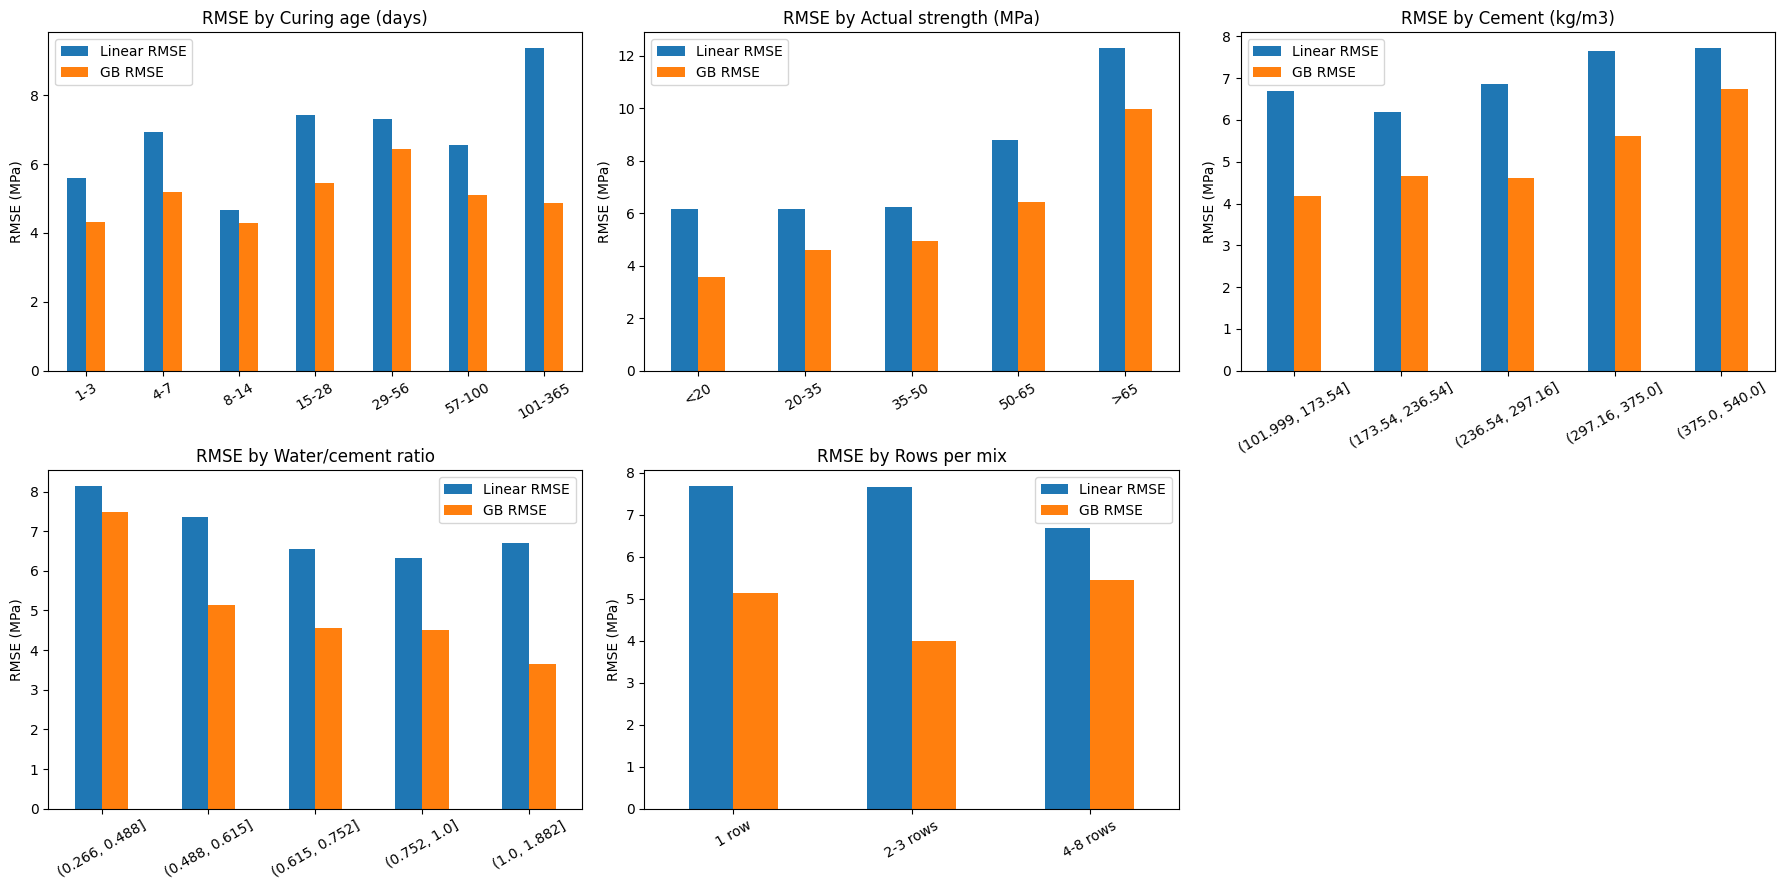

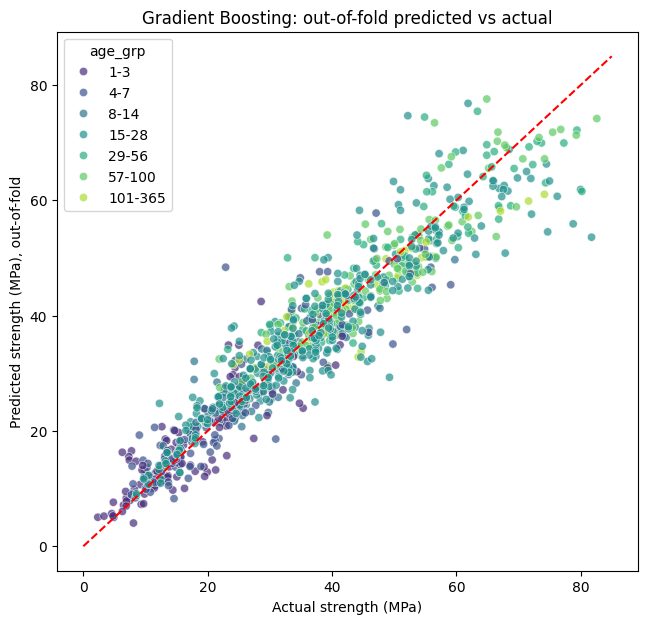


Weakest segments by absolute error (GB RMSE); overall = 5.24


,Grouping,Segment,n,GB RMSE,GB bias
11,Actual strength (MPa),>65,53,9.97,7.42
17,Water/cement ratio,"(0.266, 0.488]",203,7.48,0.22
16,Cement (kg/m3),"(375.0, 540.0]",197,6.75,0.34
4,Curing age (days),29-56,86,6.45,-0.33
10,Actual strength (MPa),50-65,140,6.44,1.53
15,Cement (kg/m3),"(297.16, 375.0]",204,5.61,-0.19
3,Curing age (days),15-28,419,5.45,0.06
24,Rows per mix,4-8 rows,654,5.45,0.25


Weakest segments by relative error (GB MAE as % of mean strength):


,Grouping,Segment,n,GB MAE,GB MAE % of mean strength,GB bias
7,Actual strength (MPa),<20,196,2.56,18.89,-1.42
0,Curing age (days),1-3,131,3.17,17.37,-0.40
1,Curing age (days),4-7,122,3.45,13.71,-0.11
2,Curing age (days),8-14,62,3.43,11.91,-0.07
20,Water/cement ratio,"(0.752, 1.0]",204,3.38,11.84,-0.37
8,Actual strength (MPa),20-35,324,3.30,11.78,-1.59
13,Cement (kg/m3),"(173.54, 236.54]",197,3.50,11.60,-0.05
12,Cement (kg/m3),"(101.999, 173.54]",205,2.96,11.52,-0.15



15 largest boosting errors:


,cement,water,age,strength,pred_gb,res_gb,pred_lin,res_lin,mix_n
357,315.0,145.0,28,81.8,53.6,28.1,52.7,29.0,1
105,362.6,164.9,7,22.9,48.4,-25.5,45.2,-22.3,6
359,451.0,165.0,28,78.8,55.9,22.9,49.1,29.7,1
120,379.5,153.9,28,52.2,74.7,-22.5,57.7,-5.5,5
119,323.7,183.8,28,74.7,54.5,20.2,58.2,16.5,4
371,200.0,190.0,28,49.2,29.3,19.9,36.3,12.9,1
138,379.5,153.9,56,54.9,74.5,-19.6,63.8,-8.9,5
137,323.7,183.8,56,80.2,61.6,18.6,64.1,16.1,4
0,540.0,162.0,28,80.0,61.9,18.1,56.3,23.7,1
203,168.0,121.8,56,32.9,50.0,-17.2,47.1,-14.3,5



Top 5% worst rows (50) shared by both models: 17
Share of boosting squared error from worst 5% of rows: 42%
Share of boosting squared error from worst 5% of mixes (21 mixes): 43%


In [15]:
# ===== 2F. Where are predictions weakest? =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

assert "df_clean" in globals(), "Run the 1D cell first (it creates df_clean)."
SEED = globals().get("SEED", 42)
feats_C = ["cement","slag","fly_ash","water","superplasticizer","coarse_agg",
           "fine_agg","age","log_age","w_c_ratio"]
best = {"learning_rate": 0.03, "max_depth": 4, "n_estimators": 400}   # tuned in 2C
rm = lambda r: np.sqrt((r**2).mean())

# --- Out-of-fold residuals (reuse 2E's res_df if present, else rebuild) ---
ok = ("res_df" in globals() and len(res_df) == len(df_clean)
      and all(c in res_df.columns for c in ["pred_lin","pred_gb","res_lin","res_gb"]))
if not ok:
    X, y, g = df_clean[feats_C], df_clean["strength"], df_clean["mix_id"]
    gkf = GroupKFold(n_splits=5)
    res_df = df_clean[["cement","water","age","w_c_ratio","mix_id","strength"]].copy()
    res_df["pred_lin"] = cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()),
                                           X, y, cv=gkf, groups=g)
    res_df["pred_gb"] = cross_val_predict(
        GradientBoostingRegressor(subsample=0.8, random_state=SEED, **best), X, y, cv=gkf, groups=g)
    res_df["res_lin"] = y - res_df["pred_lin"]
    res_df["res_gb"] = y - res_df["pred_gb"]
print("Check (expect ~7.04 and ~5.24): Linear %.2f | Boosting %.2f" %
      (rm(res_df["res_lin"]), rm(res_df["res_gb"])))

# --- Groupings ---
res_df["mix_n"] = res_df.groupby("mix_id")["strength"].transform("size")
res_df["age_grp"] = pd.cut(res_df["age"], [0,3,7,14,28,56,100,365],
                           labels=["1-3","4-7","8-14","15-28","29-56","57-100","101-365"])
res_df["str_grp"] = pd.cut(res_df["strength"], [0,20,35,50,65,100],
                           labels=["<20","20-35","35-50","50-65",">65"])
res_df["cem_grp"] = pd.qcut(res_df["cement"], 5)
res_df["wc_grp"] = pd.qcut(res_df["w_c_ratio"], 5)
res_df["mixn_grp"] = pd.cut(res_df["mix_n"], [0,1,3,8], labels=["1 row","2-3 rows","4-8 rows"])
groupings = [("age_grp","Curing age (days)"), ("str_grp","Actual strength (MPa)"),
             ("cem_grp","Cement (kg/m3)"), ("wc_grp","Water/cement ratio"),
             ("mixn_grp","Rows per mix")]

def breakdown(col):
    g = res_df.groupby(col, observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "Linear RMSE": g["res_lin"].apply(rm),
        "GB RMSE": g["res_gb"].apply(rm),
        "GB MAE": g["res_gb"].apply(lambda r: r.abs().mean()),
        "GB MAE % of mean strength": g["res_gb"].apply(lambda r: r.abs().mean()) / g["strength"].mean() * 100,
        "GB bias": g["res_gb"].mean(),
        "Linear bias": g["res_lin"].mean()}).round(2)

tables = {}
for col, title in groupings:
    tables[col] = breakdown(col)
    print(f"\n=== Error by {title} ===")
    display(tables[col])

# --- Chart 1: RMSE by segment ---
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (col, title) in zip(axes.ravel(), groupings):
    tables[col][["Linear RMSE","GB RMSE"]].plot(kind="bar", ax=ax, rot=30)
    ax.set_title(f"RMSE by {title}"); ax.set_xlabel(""); ax.set_ylabel("RMSE (MPa)")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# --- Chart 2: predicted vs actual, coloured by age ---
plt.figure(figsize=(7.5, 7))
sns.scatterplot(data=res_df, x="strength", y="pred_gb", hue="age_grp", palette="viridis", alpha=0.7)
plt.plot([0,85], [0,85], "r--")
plt.xlabel("Actual strength (MPa)"); plt.ylabel("Predicted strength (MPa), out-of-fold")
plt.title("Gradient Boosting: out-of-fold predicted vs actual"); plt.show()

# --- Ranking of weakest segments (n >= 20) ---
allseg = pd.concat([tables[c].reset_index().set_axis(["Segment"] + list(tables[c].columns), axis=1)
                    .assign(Segment=lambda d: d["Segment"].astype(str)).assign(Grouping=t)
                    for c, t in groupings], ignore_index=True)
allseg = allseg[allseg["n"] >= 20]
print("\nWeakest segments by absolute error (GB RMSE); overall = %.2f" % rm(res_df["res_gb"]))
display(allseg.sort_values("GB RMSE", ascending=False).head(8)
        [["Grouping","Segment","n","GB RMSE","GB bias"]])
print("Weakest segments by relative error (GB MAE as % of mean strength):")
display(allseg.sort_values("GB MAE % of mean strength", ascending=False).head(8)
        [["Grouping","Segment","n","GB MAE","GB MAE % of mean strength","GB bias"]])

# --- 15 worst predictions ---
res_df["abs_gb"], res_df["abs_lin"] = res_df["res_gb"].abs(), res_df["res_lin"].abs()
print("\n15 largest boosting errors:")
display(res_df.nlargest(15, "abs_gb")[["cement","water","age","strength","pred_gb",
                                       "res_gb","pred_lin","res_lin","mix_n"]].round(1))

# --- Concentration of error ---
k = int(0.05 * len(res_df))
shared = len(set(res_df.nlargest(k,"abs_gb").index) & set(res_df.nlargest(k,"abs_lin").index))
sq = (res_df["res_gb"]**2).sort_values(ascending=False)
mix_sq = res_df.groupby("mix_id")["res_gb"].apply(lambda r: (r**2).sum()).sort_values(ascending=False)
n5 = int(0.05 * len(mix_sq))
print(f"\nTop 5% worst rows ({k}) shared by both models: {shared}")
print("Share of boosting squared error from worst 5%% of rows: %.0f%%" % (sq.head(k).sum()/sq.sum()*100))
print("Share of boosting squared error from worst 5%% of mixes (%d mixes): %.0f%%" %
      (n5, mix_sq.head(n5).sum()/mix_sq.sum()*100))

Both models are unbiased on average, so the question is where and how much they err, not whether they lean one way.
Gradient Boosting is more accurate in the typical case but still produces occasional large misses. For practical use, report its error as a distribution (MAE of about 3.8 MPa, with about 7% of predictions off by more than 10 MPa) and not as a single RMSE.
Prediction is least reliable for stronger mixes. Section 2F confirms this: above 65 MPa, boosting has an RMSE of about 10 MPa and under-predicts by about 7 MPa. Its absolute error peaks at 29 to 56 days. Older specimens are not a weak spot for boosting, because the late-age weakness (101 to 365 days) belonged to the linear model.
The residuals violate independence. The data hold only 428 independent mixes, so uncertainty is larger than 1,005 rows would suggest, and the bootstrap intervals in 2C are probably too narrow. This supports using grouped validation throughout.


Limitations

Grouping by actual strength builds in regression to the mean, so some under-prediction at the top and over-prediction at the bottom would appear even for a well-calibrated model. The size of the bias above 65 MPa, and the fact that it is larger for the linear model, suggest the effect is real. The residuals-vs-predicted plot from 2E, which conditions on the prediction, is the cleaner check.
The segments overlap (high strength, high cement, low water/cement), and the above-65 group has only 53 rows from few mixes. No confidence intervals were computed for the segment RMSEs, so small differences between neighbouring segments should not be interpreted.
Explanations for why (sparse data, noise, unrecorded factors) are hypotheses, because the data cannot test them. Only the where is evidenced.
The bar charts and the predicted-vs-actual plot must appear in the notebook as visual evidence. They didn’t come through in your paste, and I haven’t seen the three residual plots from 2E either.

***2G Final comparision***

Check (expect ~7.04 for Linear C and ~5.24 for Gradient Boosting)


,RMSE,MAE,R2,RMSE reduction vs baseline (%),Errors > 10 MPa (%)
Model,,,,,
Mean baseline,16.29,13.16,-0.00,0.00,54.63
Linear C,7.04,5.52,0.81,56.78,15.72
Poly-2 Ridge,6.10,4.55,0.86,62.53,8.86
Random Forest,5.55,3.95,0.88,65.96,8.56
Gradient Boosting (tuned),5.24,3.75,0.90,67.85,6.87



RMSE with 95% cluster-bootstrap intervals (resampling mixes):


,RMSE,95% CI low,95% CI high
Mean baseline,16.29,15.45,17.08
Linear C,7.04,6.56,7.49
Poly-2 Ridge,6.10,5.56,6.73
Random Forest,5.55,5.05,6.07
Gradient Boosting (tuned),5.24,4.76,5.76


Paired RMSE differences (positive = first model is better), 95% CI:
  Linear C minus Poly-2 Ridge:  0.94 MPa  [ 0.32,  1.47]
  Linear C minus Random Forest:  1.50 MPa  [ 1.02,  1.98]
  Linear C minus Gradient Boosting (tuned):  1.80 MPa  [ 1.28,  2.32]
  Random Forest minus Gradient Boosting (tuned):  0.30 MPa  [-0.05,  0.63]


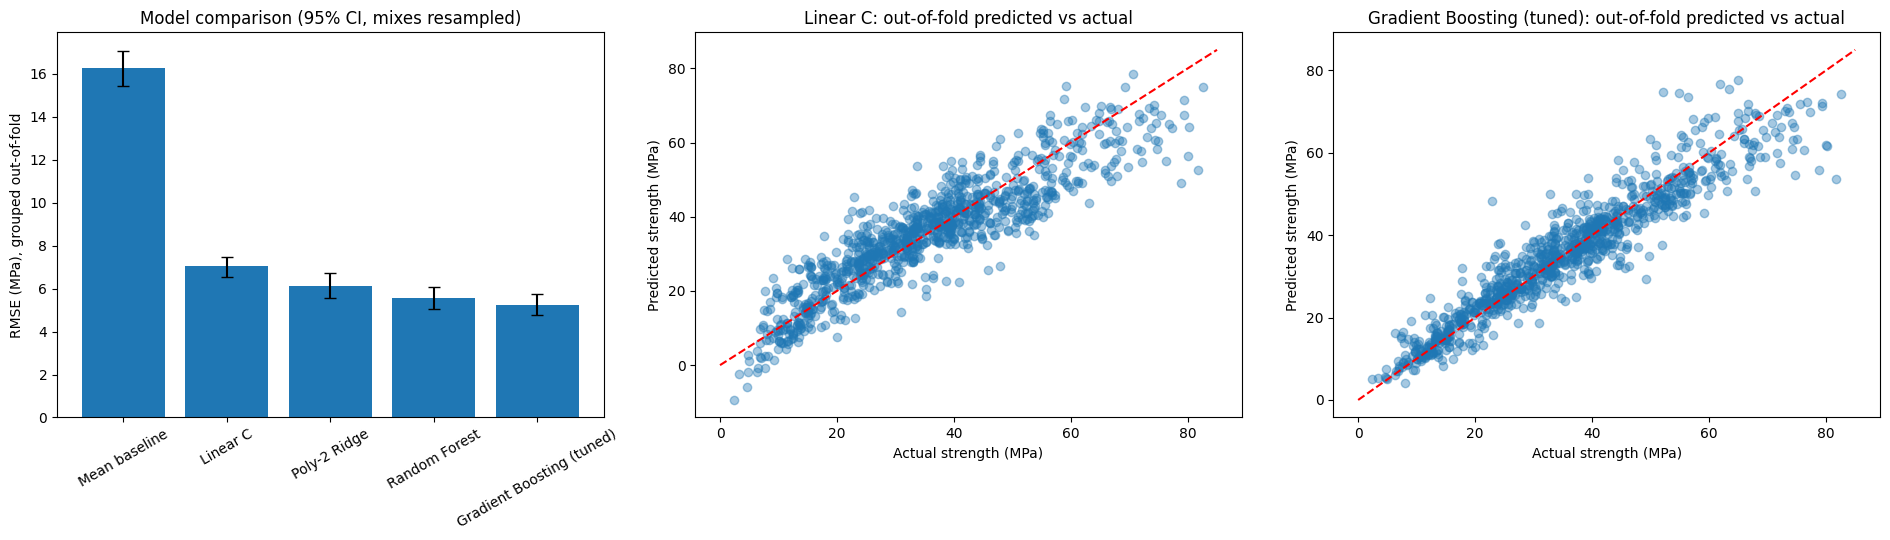

In [16]:
# ===== 2G. Final comparison: linear vs non-linear (grouped out-of-fold, all 1,005 rows) =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score

assert "df_clean" in globals(), "Run the 1D cell first (it creates df_clean)."
SEED = globals().get("SEED", 42)
feats_C = ["cement","slag","fly_ash","water","superplasticizer","coarse_agg",
           "fine_agg","age","log_age","w_c_ratio"]
best = {"learning_rate": 0.03, "max_depth": 4, "n_estimators": 400}   # tuned in 2C

X, y, g = df_clean[feats_C], df_clean["strength"], df_clean["mix_id"]
gkf = GroupKFold(n_splits=5)

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear C": make_pipeline(StandardScaler(), LinearRegression()),
    "Poly-2 Ridge": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                                  StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting (tuned)": GradientBoostingRegressor(subsample=0.8, random_state=SEED, **best),
}

# --- 1. Grouped out-of-fold predictions: every row is predicted by a model that never saw its mix ---
oof = {n: cross_val_predict(m, X, y, cv=gkf, groups=g) for n, m in models.items()}

# --- 2. Final comparison table ---
base_rmse = np.sqrt(((y - oof["Mean baseline"])**2).mean())
rows = []
for n, p in oof.items():
    e = y - p
    rows.append({"Model": n,
                 "RMSE": np.sqrt((e**2).mean()),
                 "MAE": e.abs().mean(),
                 "R2": r2_score(y, p),
                 "RMSE reduction vs baseline (%)": (1 - np.sqrt((e**2).mean()) / base_rmse) * 100,
                 "Errors > 10 MPa (%)": (e.abs() > 10).mean() * 100})
final = pd.DataFrame(rows).set_index("Model").round(2)
print("Check (expect ~7.04 for Linear C and ~5.24 for Gradient Boosting)")
display(final)

# --- 3. Cluster bootstrap: resample whole MIXES (rows of one mix are not independent) ---
codes, uniq = pd.factorize(g)
cnt = np.bincount(codes)
sse = {n: np.bincount(codes, weights=((y.values - p)**2)) for n, p in oof.items()}
B = 2000
idx = np.random.default_rng(SEED).integers(0, len(uniq), size=(B, len(uniq)))
boot = {n: np.sqrt(s[idx].sum(axis=1) / cnt[idx].sum(axis=1)) for n, s in sse.items()}

ci = pd.DataFrame({n: {"RMSE": np.sqrt(sse[n].sum() / cnt.sum()),
                       "95% CI low": np.percentile(b, 2.5),
                       "95% CI high": np.percentile(b, 97.5)} for n, b in boot.items()}).T.round(2)
print("\nRMSE with 95% cluster-bootstrap intervals (resampling mixes):")
display(ci)

print("Paired RMSE differences (positive = first model is better), 95% CI:")
pairs = [("Linear C", "Poly-2 Ridge"), ("Linear C", "Random Forest"),
         ("Linear C", "Gradient Boosting (tuned)"), ("Random Forest", "Gradient Boosting (tuned)")]
for a, b in pairs:
    d = boot[a] - boot[b]
    print(f"  {a} minus {b}: {d.mean():5.2f} MPa  [{np.percentile(d, 2.5):5.2f}, {np.percentile(d, 97.5):5.2f}]")

# --- 4. Chart: RMSE with intervals, and predicted vs actual for linear vs boosting ---
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
names = list(ci.index)
axes[0].bar(names, ci["RMSE"], yerr=[ci["RMSE"] - ci["95% CI low"], ci["95% CI high"] - ci["RMSE"]], capsize=4)
axes[0].set_ylabel("RMSE (MPa), grouped out-of-fold")
axes[0].set_title("Model comparison (95% CI, mixes resampled)")
axes[0].tick_params(axis="x", rotation=30)
for ax, n in zip(axes[1:], ["Linear C", "Gradient Boosting (tuned)"]):
    ax.scatter(y, oof[n], alpha=0.4)
    ax.plot([0, 85], [0, 85], "r--")
    ax.set_xlabel("Actual strength (MPa)")
    ax.set_ylabel("Predicted strength (MPa)")
    ax.set_title(f"{n}: out-of-fold predicted vs actual")
plt.tight_layout()
plt.show()

Every model beats the baseline by a wide margin. Even the simplest, Linear C, cuts RMSE by 57%.

Non-linear models beat the linear model, and the gap is statistically clear. The three intervals exclude 0. Boosting lowers RMSE by 1.80 MPa (26%) and MAE by 32% (5.52 to 3.75). The share of predictions off by more than 10 MPa falls from 15.7% to 6.9%, and the unexplained share of variance roughly halves (R² from 0.81 to 0.90).

The improvement comes in layers. Adding squared and interaction terms to a linear model (Poly-2 Ridge) recovers about half of the gain, and the tree ensembles recover most of the rest. This is consistent with interactions and curvature in how ingredients and age combine, which a purely linear model cannot represent.

Gradient Boosting and Random Forest cannot be separated. The paired difference is 0.30 MPa with an interval that includes 0 (−0.05 to 0.63). This agrees with the 2D result, where boosting won only 5 of 10 grouped splits. Boosting does show somewhat fewer large errors (6.9% against 8.6%), but we did not test that difference.

Intervals are wider than in 2C. Resampling mixes, not rows, gives an honest picture of the uncertainty. Boosting’s RMSE interval is about 4.8 to 5.8 MPa.

### Question 3.  Does a predictive association between cement content and strength prove what will happen in the  real-world if we change the mixture? Justify your answer.

In [17]:
import numpy as np, pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

assert "df_clean" in globals(), "Run the 1D cell first (it creates df_clean)."
SEED = globals().get("SEED", 42)
feats_C = ["cement","slag","fly_ash","water","superplasticizer","coarse_agg",
           "fine_agg","age","log_age","w_c_ratio"]
best = {"learning_rate": 0.03, "max_depth": 4, "n_estimators": 400}   # tuned in 2C
ing = ["cement","slag","fly_ash","water","superplasticizer","coarse_agg","fine_agg"]
d, y = df_clean.copy(), df_clean["strength"]

# --- Check 1: does the estimated "effect" of cement change with what we adjust for? ---
def cement_effect(feats):
    m = LinearRegression().fit(d[feats], y)
    return m.coef_[feats.index("cement")] * 10          # MPa per +10 kg/m3 of cement

sets = {
    "Cement alone":                                   ["cement"],
    "+ log(age)":                                     ["cement", "log_age"],
    "+ log(age) + water":                             ["cement", "log_age", "water"],
    "+ log(age) + all other ingredients":             ["cement", "log_age"] + [c for c in ing if c != "cement"],
    "+ log(age) + w/c ratio (water moves with cement)": ["cement", "log_age", "w_c_ratio"],
}
print("Check 1: estimated cement effect, MPa per +10 kg/m3, by adjustment set")
display(pd.Series({k: cement_effect(v) for k, v in sets.items()}, name="MPa per +10 kg").round(2).to_frame())

# --- Check 2: ingredients are tied together (a mix is 1 m3 of material) ---
d["total_kg_m3"] = d[ing].sum(axis=1)
print("\nCheck 2: total ingredient mass per m3 of concrete")
print(d["total_kg_m3"].describe().round(0).to_string())
print("\nCorrelation of cement with the other ingredients:")
print(d[ing].corr()["cement"].drop("cement").round(2).to_string())

# --- Check 3: what-if +50 kg cement; do equally 'good' models agree on the effect? ---
def whatif(delta, swap=None):
    X0 = d[feats_C].copy()
    X1 = X0.copy()
    X1["cement"] = X1["cement"] + delta
    if swap:
        X1[swap] = X1[swap] - delta
    X1["w_c_ratio"] = X1["water"] / X1["cement"]        # keep the engineered feature consistent
    return X0, X1

models = {
    "Linear C": make_pipeline(StandardScaler(), LinearRegression()),
    "Poly-2 Ridge": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                                  StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(subsample=0.8, random_state=SEED, **best),
}
scen = {"A: +50 kg cement, all else fixed": None,
        "B: +50 kg cement, -50 kg fine aggregate": "fine_agg"}
rows = []
for name, m in models.items():
    m.fit(d[feats_C], y)                                 # fitted on all rows: diagnostic only
    row = {"Model": name}
    for label, swap in scen.items():
        X0, X1 = whatif(50, swap)
        diff = m.predict(X1) - m.predict(X0)
        row[label + ": mean MPa"] = diff.mean()
        row[label + ": SD across mixes"] = diff.std()
    rows.append(row)
print("\nCheck 3: predicted change in strength (MPa) from the what-if changes")
pd.set_option("display.width", 250)
display(pd.DataFrame(rows).set_index("Model").round(2))

# --- Is scenario A a mix that exists in the data? ---
X0, X1 = whatif(50)
tot1 = d["total_kg_m3"] + 50
print("\nScenario A realism:")
print("  Share with total mass above the observed 99th percentile: %.0f%%" %
      ((tot1 > d["total_kg_m3"].quantile(0.99)).mean() * 100))
print("  Share with water/cement ratio below the observed 1st percentile: %.0f%%" %
      ((X1["w_c_ratio"] < d["w_c_ratio"].quantile(0.01)).mean() * 100))

Check 1: estimated cement effect, MPa per +10 kg/m3, by adjustment set


,MPa per +10 kg
Cement alone,0.76
+ log(age),0.76
+ log(age) + water,0.73
+ log(age) + all other ingredients,1.32
+ log(age) + w/c ratio (water moves with cement),0.32



Check 2: total ingredient mass per m3 of concrete
count    1005.0
mean     2341.0
std        65.0
min      2195.0
25%      2290.0
50%      2348.0
75%      2388.0
max      2551.0

Correlation of cement with the other ingredients:
slag               -0.30
fly_ash            -0.39
water              -0.06
superplasticizer    0.06
coarse_agg         -0.09
fine_agg           -0.25

Check 3: predicted change in strength (MPa) from the what-if changes


,"A: +50 kg cement, all else fixed: mean MPa","A: +50 kg cement, all else fixed: SD across mixes","B: +50 kg cement, -50 kg fine aggregate: mean MPa","B: +50 kg cement, -50 kg fine aggregate: SD across mixes"
Model,,,,
Linear C,6.77,0.76,5.09,0.76
Poly-2 Ridge,6.92,3.69,4.91,2.88
Random Forest,3.94,4.65,4.53,5.02
Gradient Boosting,4.11,3.43,4.78,4.02



Scenario A realism:
  Share with total mass above the observed 99th percentile: 16%
  Share with water/cement ratio below the observed 1st percentile: 3%



Does a predictive association between cement content and strength prove what will happen in the real-world if we change the mixture?

No, it does not prove real-world causation, for three major reasons:

##Confounding and Omitted Variable Bias (Check 1):
The apparent "effect" of cement on strength shifts dramatically (from $0.32$ to $1.32\text{ MPa}$) depending on which other ingredients and variables (like age and water) are adjusted for in the model. Observational data reflects historical mix designs, not controlled random experiments.

##Physical and Compositional Constraints (Check 2 & Realism):
 Concrete is constrained by volume ($\text{1 m}^3$). Naively increasing cement while keeping everything else fixed (Scenario A) creates physically unrealistic mixtures, forcing $16\%$ of data points past normal mass limits. In reality, ingredients must be substituted (e.g., trading fine aggregate for cement, as in Scenario B).


##Model Instability under Interventions (Check 3):
  Different models (Linear vs. Random Forest/Gradient Boosting) predict different strength gains for the exact same +50 kg cement intervention. Predictive models find historical correlations, but they do not inherently understand the underlying physical laws of how chemical hydration works under a new intervention.